# Gas chromatography: visualization and preprocessing

Read and validate a LabSolutions export, visualize chromatograms and compound profiles, then estimate a baseline, detect peak candidates, and integrate signed corrected intensities over disjoint regions.

The first five parts cover settings, file reading, data extraction, plotting, and program execution. Additional sections provide a normalized overlay, a compound composition bar chart, and a compound fingerprint heatmap.

## How to run

Open this notebook from the project root. The supplied export is stored at:

```text
data/Gaschroma.txt
```

Run the cells from top to bottom. Install the tested dependencies in your notebook environment:

```python
%pip install -r requirements.txt
```

The supplied file contains separate sections for sample information, a table of 65 detected peaks, compound results, and the raw signal. The data needed for this step are in the following section:

```text
[Chromatogram (Ch1)]
```

Its two columns contain retention time in minutes and signal intensity. The physical unit of intensity is not specified in this export.


## Updated preprocessing and integration workflow

Sections 12-21 implement the expanded course description:

1. Locate a dominant early-peak candidate and choose an analysis start after sustained recovery.
2. Select background candidates automatically from low-signal bins or from manual intervals/anchors.
3. Fit polynomial coefficients with `np.polyfit` and evaluate the baseline with `np.polyval`.
4. Subtract the baseline from the unsmoothed raw signal while preserving signed negatives.
5. Detect initial peak candidates before assigning their integration regions.
6. Use inter-peak minima to cap neighboring regions so that time intervals do not overlap.
7. Integrate signed, unsmoothed data and flag uncertain boundaries or elevated inter-peak valleys.

The default is a cubic polynomial. Its degree and background candidates are configurable;
this least-squares model is not a claim of a universally optimal physical baseline. The
previous asymmetric least-squares method remains available with `baseline_method="asls"`.

The original five plots and exported compound percentages remain separate from these new
signal-based peak areas. Candidate peaks do not receive chemical names.

See the [execution guide](README.md) for headless execution, result files, and interpretation limits. All 21 code cells and all analysis stages from the supplied notebook are retained.

## 1. Libraries and settings

The input filename and folder, display range, figure size, and saving option are defined at the beginning of the program. The default input directory is `data`, relative to the project root. For another input file, change the settings; the functions can be reused.

The 4-to-16-minute range is selected to display the peaks in more detail. The full chromatogram is also plotted separately.

The additional settings define a dictionary of real sample labels and file paths. With one file, the new plots are single-sample previews. Add reference and mixture files to `SAMPLE_FILES` to use the same functions for comparisons.

`COMPOUND_METRIC` selects the basis of the bar chart and heatmap:

- `reported_percent`: use the instrument-exported `Conc. %` values directly.
- `area_percent`: calculate each compound's area as a percentage of the total area in the **Compound Results** table.

The second option has a different denominator from all detected peaks: unassigned peaks outside the compound table are excluded. It is an uncorrected area fraction, not a validated concentration or an oil mixing fraction.


`PREPROCESSING_SETTINGS` contains every preprocessing control. The automatic analysis
start is independent of the original 4-16 minute display window. To use a fixed start,
set `analysis_start_min` to a number. The configured background interval must be a quiet
post-apex region; inspect the early-peak diagnostic when processing a different file.


Polynomial settings are `baseline_method`, `polynomial_degree`, and the point-selection
controls. For manual selection, use intervals in `baseline_intervals_min` or observed-time
anchors in `baseline_anchor_times_min`. Automatic selection uses the lowest 15% of values
in each 0.35-minute bin; inspect the selected points because low signal is not proof of a
peak-free background. The integration rule is `trapezoid` by default; `simpson` is optional.
The trapezoidal rule and Simpson's rule are different numerical methods.

In [1]:
from pathlib import Path
import csv
import json
import hashlib
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "semibold",
    "figure.dpi": 110,
    "savefig.bbox": "tight",
})

from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.signal import find_peaks, savgol_filter
from scipy.integrate import trapezoid, simpson

INPUT_DIRECTORY = Path("data")
INPUT_FILENAME = "Gaschroma.txt"
INPUT_PATH = INPUT_DIRECTORY / INPUT_FILENAME
ENCODING = "utf-8-sig"
SECTION = "[Chromatogram (Ch1)]"

START_TIME = 4.0
END_TIME = 16.0
FIGURE_SIZE = (11, 4)

SAVE_PLOTS = True
OUTPUT_DIRECTORY = Path("results")
FULL_PLOT_FILENAME = "Gaschroma_full.png"
ZOOM_PLOT_FILENAME = "Gaschroma_zoom.png"
DPI = 200

# Additional visualization settings
SAMPLE_FILES = {
    "231221_C37": INPUT_PATH,
    # Add actual files here when available, for example:
    # "Reference oil A": INPUT_DIRECTORY / "reference_A.txt",
    # "Reference oil B": INPUT_DIRECTORY / "reference_B.txt",
    # "Unknown mixture": INPUT_DIRECTORY / "unknown_mixture.txt",
}
COMPOUND_SECTION = "[Compound Results(Ch1)]"
NORMALIZATION_START = START_TIME
NORMALIZATION_END = END_TIME
COMPOUND_METRIC = "reported_percent"  # Alternative: "area_percent"
TOP_COMPOUNDS = 12
ANNOTATE_HEATMAP = True
OVERLAY_PLOT_FILENAME = "Gaschroma_normalized_overlay.png"
BAR_PLOT_FILENAME = "Gaschroma_compound_bars.png"
HEATMAP_PLOT_FILENAME = "Gaschroma_compound_heatmap.png"

# Preprocessing settings: all times are in minutes.
# A dominant early signal is a candidate, not a confirmed solvent identity.
PREPROCESSING_SETTINGS = {
    'detect_early_peak': True,
    'early_search_end_min': 3.0,
    'background_interval_min': (2.75, 3.0),
    'min_early_prominence': 1000.0,
    'min_early_dominance': 20.0,
    'return_fraction_of_prominence': 1e-06,
    'return_absolute_margin': 100.0,
    'return_noise_factor': 6.0,
    'return_hold_min': 0.08,
    'post_recovery_padding_min': 0.05,
    'analysis_start_min': None,
    'analysis_end_min': None,
    'smooth_window_min': 0.006,
    'smooth_polyorder': 2,
    'sampling_relative_tolerance': 0.05,
    'baseline_lambda': 100000000.0,
    'baseline_p': 0.001,
    'baseline_max_iterations': 30,
    'baseline_tolerance': 1e-05,
    'noise_floor': 1.0,
    'negative_sigma_factor': 3.0,
    'peak_min_prominence': 1000.0,
    'peak_noise_factor': 6.0,
    'peak_min_distance_min': 0.04,
    'peak_min_width_min': 0.003,
    'plot_start_min': 4.0,
    'plot_end_min': 16.0,
    'baseline_method': 'polynomial',
    'polynomial_degree': 3,
    'baseline_point_selection': 'automatic',
    'baseline_bin_width_min': 0.35,
    'baseline_low_quantile': 0.15,
    'baseline_intervals_min': [],
    'baseline_anchor_times_min': [],
    'boundary_relative_height': 0.01,
    'boundary_noise_factor': 3.0,
    'overlap_valley_fraction': 0.15,
    'integration_method': 'trapezoid',
}
RUN_PEAK_PREVIEW = True
SAVE_PREPROCESSING_TABLES = True
PREPROCESSING_OUTPUT_PREFIX = "Gaschroma_preprocessing"

# Polynomial mode follows the course method. Use "asls" for the prior alternative.
# For manual background selection, set baseline_point_selection to "manual" and
# enter non-peak intervals or observed-time anchors in the lists above.
# Cubic degree is a configurable starting model, not an automatically optimal choice.

## 2. Read and validate the export

Read the supplied UTF-8 text file, then locate sections by their names. The helpers check metadata counts, array shapes, finite values, and strictly increasing retention times. Invalid data raise an explanatory error instead of being silently removed, sorted, or interpolated.

Negative detector intensities are valid in this export and are preserved. Neither baseline correction nor smoothing is applied.

In [2]:
def read_file(file_path, encoding="utf-8-sig"):
    """Read a local export, allowing a UTF-8 byte-order mark."""
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError(
            f"Data file not found: {path}. Run from the project root "
            "or update INPUT_DIRECTORY and INPUT_FILENAME."
        )
    return path.read_text(encoding=encoding).splitlines()


def extract_section(lines, section):
    """Find one named section without assuming fixed line numbers."""
    matches = [i for i, line in enumerate(lines) if line.strip() == section]
    if len(matches) != 1:
        raise ValueError(f"Expected exactly one section {section}; found {len(matches)}.")
    block = []
    for line in lines[matches[0] + 1:]:
        stripped = line.strip()
        if stripped.startswith("[") and stripped.endswith("]"):
            break
        if stripped:
            block.append(line)
    return block


def reported_count(lines, key):
    """Require a single, positive integer count in the section metadata."""
    values = []
    for line in lines:
        fields = line.split("\t")
        if fields[0].strip() == key:
            if len(fields) != 2:
                raise ValueError(f"Malformed count metadata: {key}.")
            values.append(fields[1].strip())
    if len(values) != 1:
        raise ValueError(f"Expected exactly one {key} metadata entry.")
    try:
        count = int(values[0])
    except ValueError as error:
        raise ValueError(f"{key} must be an integer.") from error
    if count <= 0:
        raise ValueError(f"{key} must be positive.")
    return count


def validate_chromatogram(retention_time, intensity):
    """Reject incomplete, non-finite, or out-of-order signal arrays."""
    time = np.asarray(retention_time, dtype=float)
    signal = np.asarray(intensity, dtype=float)
    if time.ndim != 1 or signal.shape != time.shape or time.size < 2:
        raise ValueError("Retention time and intensity must be matching 1D arrays with at least two points.")
    if not np.isfinite(time).all() or not np.isfinite(signal).all():
        raise ValueError("Retention time and intensity must contain only finite values.")
    if np.any(np.diff(time) <= 0):
        raise ValueError("Retention times must be strictly increasing; duplicate times are not accepted.")
    # Negative detector values are allowed; the recorded baseline is preserved.
    return time, signal


def select_window(retention_time, intensity, start_time=None, end_time=None):
    """Select a finite time window without modifying the source arrays."""
    time, signal = validate_chromatogram(retention_time, intensity)
    for bound in (start_time, end_time):
        if bound is not None and not np.isfinite(bound):
            raise ValueError("Time-window limits must be finite.")
    if start_time is not None and end_time is not None and start_time >= end_time:
        raise ValueError("The start time must be less than the end time.")
    mask = np.ones(time.size, dtype=bool)
    if start_time is not None:
        mask &= time >= start_time
    if end_time is not None:
        mask &= time <= end_time
    if np.count_nonzero(mask) < 2:
        raise ValueError("The selected time window must contain at least two measurement points.")
    return time[mask], signal[mask]

## 3. Data-extraction function

The function first finds the signal section, then locates the column header. It therefore does not depend on fixed line numbers. Reading stops when the next section begins.

Time values in the file use decimal commas. Each comma is replaced with a decimal point so that the values can be converted to numbers.

The function returns two numeric arrays: retention time and intensity. Matching indices in the arrays refer to the same measurement point. The number of extracted points is checked against the count recorded in the file so that an incomplete file is not processed silently.


In [3]:
def extract_chromatogram(lines, section="[Chromatogram (Ch1)]"):
    """Parse the complete two-column chromatogram and validate its point count."""
    block = extract_section(lines, section)
    rows = [[field.strip() for field in row] for row in csv.reader(block, delimiter="\t")]
    headers = [i for i, row in enumerate(rows) if row == ["R.Time (min)", "Intensity"]]
    if len(headers) != 1:
        raise ValueError("Expected one 'R.Time (min)' / 'Intensity' column header.")
    header_index = headers[0]
    expected = reported_count(block[:header_index], "# of Points")
    numeric_rows = []
    for row_number, row in enumerate(rows[header_index + 1:], start=1):
        if len(row) != 2:
            raise ValueError(f"Signal row {row_number} must contain exactly two columns.")
        try:
            numeric_rows.append([float(value.replace(",", ".")) for value in row])
        except ValueError as error:
            raise ValueError(f"Signal row {row_number} contains a non-numeric value.") from error
    if len(numeric_rows) != expected:
        raise ValueError(f"Expected {expected} signal points; read {len(numeric_rows)}.")
    data = np.asarray(numeric_rows, dtype=float)
    return validate_chromatogram(data[:, 0], data[:, 1])

## 4. Plotting function

The horizontal axis shows retention time in minutes; the vertical axis shows signal intensity. Without time limits, all points are plotted. With a start and end time, only points within that range are selected for plotting. The original arrays remain complete.

For the zoomed view, the vertical scale is calculated from the selected points. This prevents smaller peaks from being compressed by the very large peak near the beginning of the full chromatogram.

The function returns the figure so that the main program can save it.


In [4]:
def plot_chromatogram(
    retention_time, intensity, start_time=None, end_time=None,
    figure_size=(11, 4), title="Chromatogram",
):
    """Plot the full signal or a selected window using the original intensities."""
    time, signal = select_window(retention_time, intensity, start_time, end_time)
    fig, ax = plt.subplots(figsize=figure_size, layout="constrained")
    ax.plot(time, signal, color="#176B87", linewidth=0.8)
    ax.set_xlabel("Retention time [min]")
    ax.set_ylabel("Detector intensity [export units]")
    ax.set_title(title)
    ax.set_axisbelow(True)
    ax.grid(alpha=0.2)
    ax.margins(x=0)
    return fig

## 5. Running the program

The main program calls the three functions in order: read the file, extract the data, and plot the chromatogram. It prints the number of points and the actual time range, then creates a full plot and a plot of the selected time range.

If saving is enabled, both images are saved in this folder:

```text
results
```

Change the display range or input filename in the settings cell. After changing the settings, run the cells again from the top.


File: data/Gaschroma.txt
Measurement points: 25,500
Time range: 0.00017 to 16.99950 min


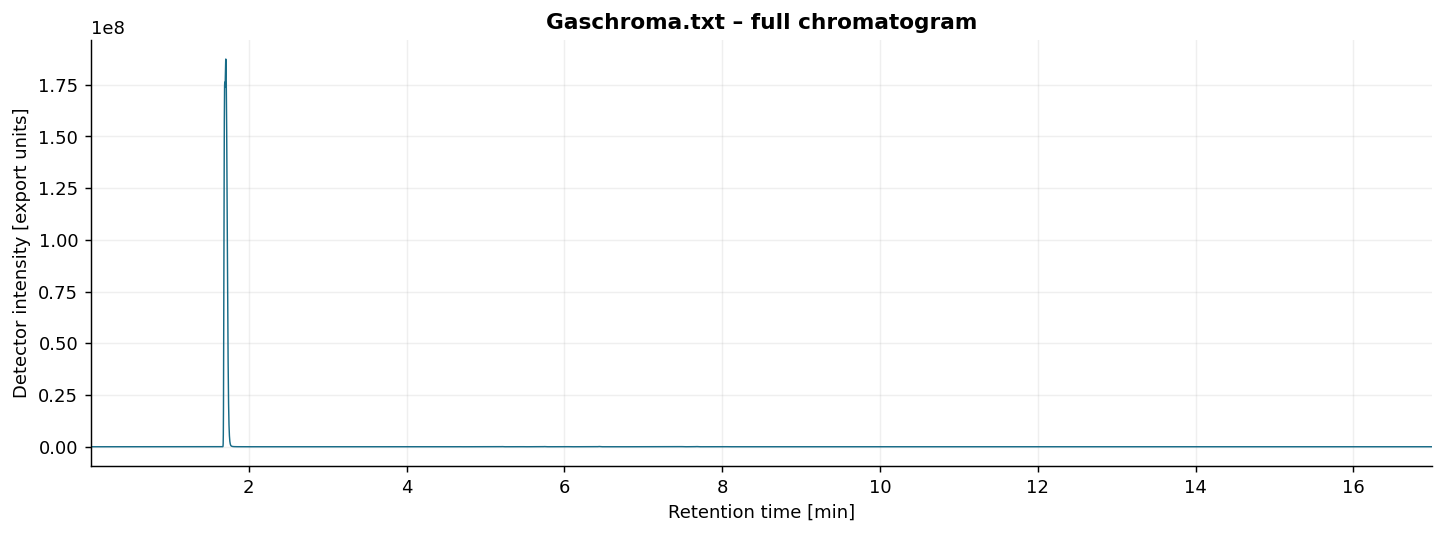

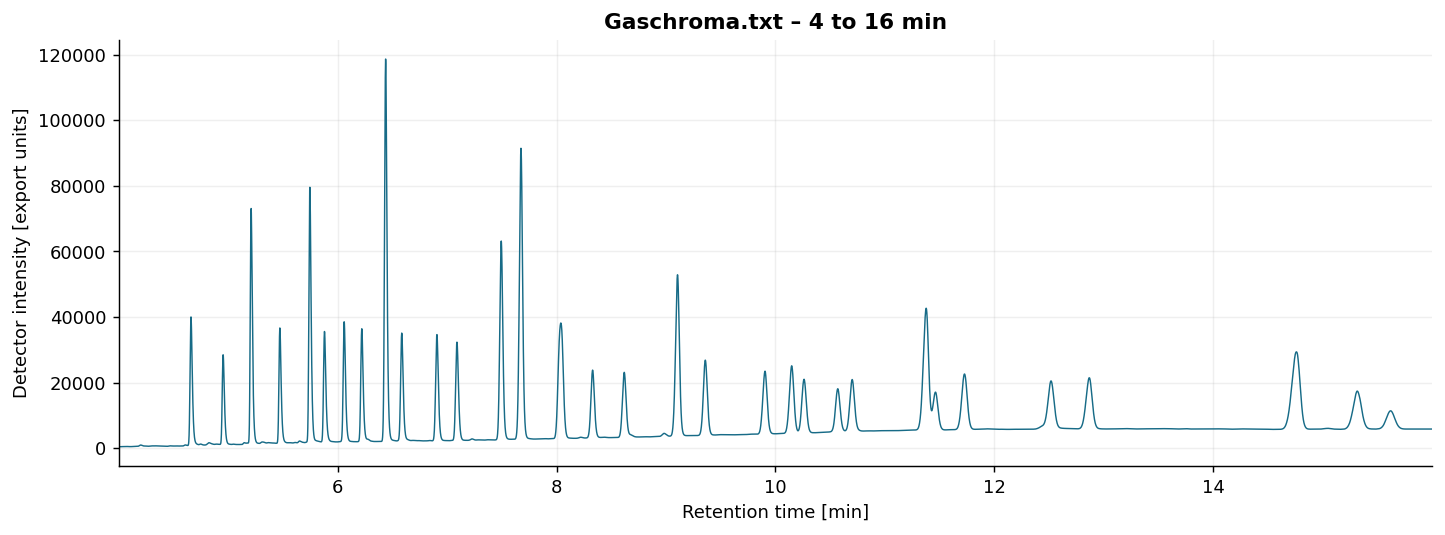

In [5]:
def main():
    lines = read_file(INPUT_PATH, ENCODING)
    retention_time, intensity = extract_chromatogram(lines, SECTION)

    print(f"File: {INPUT_PATH}")
    print(f"Measurement points: {len(retention_time):,}")
    print(f"Time range: {retention_time.min():.5f} to {retention_time.max():.5f} min")

    full_figure = plot_chromatogram(
        retention_time, intensity,
        figure_size=FIGURE_SIZE,
        title=f"{INPUT_FILENAME} – full chromatogram",
    )
    zoom_figure = plot_chromatogram(
        retention_time, intensity,
        start_time=START_TIME, end_time=END_TIME,
        figure_size=FIGURE_SIZE,
        title=f"{INPUT_FILENAME} – {START_TIME:g} to {END_TIME:g} min",
    )

    if SAVE_PLOTS:
        OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
        full_figure.savefig(OUTPUT_DIRECTORY / FULL_PLOT_FILENAME, dpi=DPI)
        zoom_figure.savefig(OUTPUT_DIRECTORY / ZOOM_PLOT_FILENAME, dpi=DPI)

    plt.show()


main()


## Results for the supplied file

| Measurement | Result |
|---|---:|
| Number of signal points | 25,500 |
| First recorded time, minutes | 0.00017 |
| Last recorded time, minutes | 16.99950 |
| Points in the 4-to-16-minute view | 18,000 |

Actual times are read from the data column. The 17-minute value is the nominal end time recorded in the file header.


# Additional scientific visualizations

The supplied file contains one sample, 35 compound rows, and 31 positive `Conc. %` values. The exported percentages sum to 100.000% in this file. The example sample label comes from the export's sample information; no oil identity is assigned.

These views answer different questions:

| View | What it shows | Current dataset |
|---|---|---|
| Normalized overlay | Peak positions and signal shapes on a common relative scale | One normalized trace; overlays appear when more files are loaded |
| Compound bar chart | Reported compound values, with the largest values displayed | Top 12 of 31 positive compound labels |
| Compound heatmap | A shared scale across the full selected compound profile | One-row preview; one row per real sample when more files are loaded |

The raw full and zoomed chromatograms above remain the starting point for interpreting the signal.


## 6. Read compound results and load real samples

The signal section and the compound table contain different information. The first has 25,500 measurement points; the second contains the instrument's named compound results.

The parser reads the compound table by its section and column headers. It preserves labels exactly, including `C18:1 cis/trans`, `C18:2 cis/trans`, `C18:3n3`, and `C18:3n6`. A combined cis/trans report entry is not split into invented components.

Each configured sample is loaded from its own file. Duplicate file paths and byte-identical copies under different names are rejected. A renamed copy is not an independent measurement.


In [6]:
def extract_compound_results(lines, section="[Compound Results(Ch1)]"):
    """Read the named compound table; preserve labels and explicit zeros."""
    block = extract_section(lines, section)
    rows = [[field.strip() for field in row] for row in csv.reader(block, delimiter="\t")]
    headers = [i for i, row in enumerate(rows) if row and row[0] == "ID#"]
    if len(headers) != 1:
        raise ValueError("Expected exactly one compound table header beginning with 'ID#'.")
    header_index = headers[0]
    header = rows[header_index]
    required = {"ID#", "Name", "R.Time", "Area", "Conc. %"}
    if not required.issubset(header) or len(header) != len(set(header)):
        raise ValueError("The compound table has missing or duplicate column names.")
    expected = reported_count(block[:header_index], "# of IDs")
    compounds = []
    ids = []
    for row_number, fields in enumerate(rows[header_index + 1:], start=1):
        if len(fields) != len(header):
            raise ValueError(f"Compound row {row_number} has {len(fields)} columns; expected {len(header)}.")
        row = dict(zip(header, fields))
        try:
            compound_id = int(row["ID#"])
            values = [float(row[name].replace(",", ".")) for name in ("R.Time", "Area", "Conc. %")]
        except ValueError as error:
            raise ValueError(f"Compound row {row_number} contains a non-numeric value.") from error
        if compound_id <= 0 or not np.isfinite(values).all() or any(value < 0 for value in values):
            raise ValueError(f"Compound row {row_number} requires a positive ID and finite, nonnegative values.")
        ids.append(compound_id)
        compounds.append({
            "name": row["Name"],
            "retention_time": values[0],
            "area": values[1],
            "reported_percent": values[2],
        })
    if len(compounds) != expected:
        raise ValueError(f"Expected {expected} compound rows; read {len(compounds)}.")
    names = [row["name"] for row in compounds]
    if any(not name for name in names) or len(set(names)) != len(names) or len(set(ids)) != len(ids):
        raise ValueError("Compound IDs and labels must be present and unique within each file.")
    return compounds


def load_samples(sample_files, encoding, signal_section, compound_section):
    """Load genuine exports; reject duplicate paths or byte-identical copies."""
    if not sample_files:
        raise ValueError("Configure at least one sample file.")
    if any(not isinstance(label, str) or not label.strip() for label in sample_files):
        raise ValueError("Sample labels must be nonempty strings.")
    paths = [Path(path).resolve() for path in sample_files.values()]
    if len(paths) != len(set(paths)):
        raise ValueError("Different sample labels must refer to different files.")
    samples = {}
    fingerprints = set()
    for label, path in zip(sample_files, paths):
        lines = read_file(path, encoding)
        fingerprint = hashlib.sha256(path.read_bytes()).hexdigest()
        if fingerprint in fingerprints:
            raise ValueError("Byte-identical export files cannot be used as independent samples.")
        fingerprints.add(fingerprint)
        retention_time, intensity = extract_chromatogram(lines, signal_section)
        samples[label] = {
            "retention_time": retention_time,
            "intensity": intensity,
            "compounds": extract_compound_results(lines, compound_section),
        }
    return samples

## 7. Normalize and overlay chromatograms

For each sample, select the same time window and divide the intensity by the maximum **inside that window**:

$$I_{\mathrm{norm},s}(t)=\frac{I_s(t)}{\max_{u\in W} I_s(u)},\qquad W=[4,16]\ \mathrm{min}.$$

Using the full-run maximum would make the very large early peak dominate the scale in this file. Window-based scaling keeps the later peaks visible. The original intensities are retained, and no baseline subtraction or smoothing is applied.

The result is a visual comparison of signal shapes. A normalized height of 0.5 means half the largest intensity in that sample's selected window; it does **not** mean 50% concentration or 50% oil content.

The function keeps each sample's original retention times. It does not automatically shift or align peaks. Compare runs measured under compatible chromatographic conditions and investigate shifts before interpreting peak matches.


In [7]:
def normalize_signal(retention_time, intensity, start_time, end_time):
    """Scale by the maximum inside a fully covered comparison window."""
    time, signal = validate_chromatogram(retention_time, intensity)
    selected_time, selected_signal = select_window(time, signal, start_time, end_time)
    if start_time < time[0] or end_time > time[-1]:
        raise ValueError("Every sample must cover the complete normalization window.")
    maximum = selected_signal.max()
    if maximum <= 0:
        raise ValueError("Normalization requires a positive signal maximum.")
    return selected_time, selected_signal / maximum


def plot_normalized_overlay(samples, start_time, end_time, figure_size):
    """Compare shapes on a shared window without changing retention times."""
    if not samples:
        raise ValueError("At least one sample is required for an overlay.")
    traces = [
        (label, *normalize_signal(sample["retention_time"], sample["intensity"], start_time, end_time))
        for label, sample in samples.items()
    ]
    fig, ax = plt.subplots(figsize=figure_size, layout="constrained")
    for label, time, normalized in traces:
        ax.plot(time, normalized, linewidth=0.9, alpha=0.9, label=label)
    ax.set_xlabel("Retention time [min]")
    ax.set_ylabel("Window-normalized intensity")
    title = "Normalized chromatogram overlay" if len(samples) > 1 else "Normalized chromatogram - one sample"
    ax.set_title(f"{title}\nMaximum scaling within {start_time:g}-{end_time:g} min")
    ax.set_xlim(start_time, end_time)
    ax.set_axisbelow(True)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
    return fig

## 8. Build comparable compound profiles

Rows correspond to samples and columns correspond to exact compound labels. The default values come directly from `Conc. %` in the report. They are instrument-calculated results; their calibration quality is not established by this notebook.

The optional area mode calculates:

$$p_{i,s}^{\mathrm{area}}=100\,\frac{A_{i,s}}{\sum_{j\in\mathrm{Compound\ Results}} A_{j,s}}.$$

The denominator includes only the named compounds in that table. This calculation does not compensate for differences in detector response.

A missing compound row is stored as a missing value. An explicit zero from the report remains zero. A zero result does not by itself prove chemical absence. Columns that are zero in every loaded sample are omitted from the plots; the full extracted records are retained in `samples`.


In [8]:
def build_compound_matrix(samples, metric="reported_percent"):
    """Align compounds by exact report labels; keep missing entries as NaN."""
    if not samples:
        raise ValueError("At least one sample is required to build a compound matrix.")
    if metric not in {"reported_percent", "area_percent"}:
        raise ValueError("Choose 'reported_percent' or 'area_percent'.")
    sample_names = list(samples)
    profiles = []
    compound_names = []
    for sample in samples.values():
        compounds = sample["compounds"]
        names = [row["name"] for row in compounds]
        if not names or any(not name for name in names) or len(set(names)) != len(names):
            raise ValueError("Each sample needs nonempty, unique compound labels.")
        if metric == "reported_percent":
            values = np.array([row["reported_percent"] for row in compounds])
            value_label = "Instrument-reported Conc. %"
        elif metric == "area_percent":
            areas = np.array([row["area"] for row in compounds])
            if areas.sum() <= 0:
                raise ValueError("The reported compound areas must have a positive sum.")
            values = 100 * areas / areas.sum()
            value_label = "Area share of reported compounds [%]"
        else:
            raise ValueError("Choose 'reported_percent' or 'area_percent'.")
        if not np.isfinite(values).all() or (values < 0).any():
            raise ValueError("Compound values must be finite and nonnegative.")

        profile = dict(zip([row["name"] for row in compounds], values))
        profiles.append(profile)
        for name in profile:
            if name not in compound_names:
                compound_names.append(name)

    # Keep compounds with a positive value in at least one loaded sample.
    compound_names = [name for name in compound_names if any(profile.get(name, 0) > 0 for profile in profiles)]
    if not compound_names:
        raise ValueError("No positive compound values are available for plotting.")
    matrix = np.array([[profile.get(name, np.nan) for name in compound_names] for profile in profiles])
    return sample_names, compound_names, matrix, value_label

## 9. Compound composition bar chart

The chart displays the largest values across the loaded samples. For the default settings, it shows 12 compound labels. Each sample has its own bar color.

The displayed subset is **not renormalized** to 100%. Each bar keeps its original reported value and the report's original percentage basis. Missing entries are not plotted.

Use these bars to compare compound profiles. A bar labeled 7.39% for `C24:0` describes the reported compound percentage in this file; it does not describe the share of an oil in a mixture.


In [9]:
def plot_compound_bars(sample_names, compound_names, matrix, value_label, top_n=12):
    """Plot the largest reported values without renormalizing the displayed subset."""
    if isinstance(top_n, bool) or not isinstance(top_n, (int, np.integer)) or top_n <= 0:
        raise ValueError("TOP_COMPOUNDS must be a positive integer.")
    order = np.argsort(-np.nanmax(matrix, axis=0), kind="stable")[:top_n]
    names = [compound_names[index] for index in order]
    fig, ax = plt.subplots(figsize=(11, max(4, len(names) * 0.42 + 1.4)))
    y = np.arange(len(names))
    height = 0.8 / len(sample_names)
    colors = plt.get_cmap("tab10")
    for index, sample_name in enumerate(sample_names):
        offset = (index - (len(sample_names) - 1) / 2) * height
        ax.barh(y + offset, matrix[index, order], height=height,
                color=colors(index % 10), label=sample_name)
    if len(sample_names) == 1:
        ax.bar_label(ax.containers[0], fmt="%.3f", padding=4, fontsize=9)
        ax.margins(x=0.12)
    ax.set_yticks(y, names)
    ax.invert_yaxis()
    ax.set_xlabel(value_label)
    ax.set_ylabel("Compound label from the instrument report")
    ax.set_title(f"Compound composition - top {len(names)} of {len(compound_names)} positive labels")
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.legend(frameon=False, loc="lower right")
    fig.tight_layout()
    return fig

## 10. Compound fingerprint heatmap

The heatmap includes every compound with a positive value in at least one loaded sample. All rows share one color scale, so the same color means the same percentage value across samples. No separate scaling is applied to each row.

Grey cells marked `NA` represent missing table entries; numeric zero represents an explicit zero from the report. Values are printed inside the cells for small matrices.

With one supplied file, the figure is a single-sample preview. With multiple reference oils and mixtures, the rows show similarities and differences in their reported compound profiles. The visualization does not classify oils or estimate mixture fractions automatically.


In [10]:
def plot_compound_heatmap(sample_names, compound_names, matrix, value_label, annotate=True):
    """Use a shared percentage scale for all samples; distinguish missing from zero."""
    fig, ax = plt.subplots(figsize=(max(10, len(compound_names) * 0.52), max(3.4, len(sample_names) * 0.6 + 2.5)))
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("#dddddd")
    maximum = np.nanmax(matrix)
    image = ax.imshow(np.ma.masked_invalid(matrix), aspect="auto", cmap=cmap, vmin=0, vmax=maximum)
    ax.set_xticks(np.arange(len(compound_names)), compound_names, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(np.arange(len(sample_names)), sample_names)
    title = "Compound fingerprints" if len(sample_names) > 1 else "Compound fingerprint - single-sample preview"
    ax.set_title(title)
    ax.set_xlabel("Compound label from the instrument report")
    colorbar = fig.colorbar(image, ax=ax, pad=0.015, fraction=0.035)
    colorbar.set_label(value_label)
    if annotate and matrix.size <= 200:
        for row in range(matrix.shape[0]):
            for column in range(matrix.shape[1]):
                value = matrix[row, column]
                text = "NA" if np.isnan(value) else f"{value:.2f}"
                color = "#444444" if np.isnan(value) else ("white" if value < maximum * 0.55 else "black")
                ax.text(column, row, text, ha="center", va="center", fontsize=7, color=color)
    fig.tight_layout()
    return fig

## 11. Run the additional visualizations

This cell loads the configured real files, prints the compound-table summary, and produces the three added figures. If saving is enabled, the images are saved alongside the existing plots in `results`.

For this file, the reported table has 35 rows, 31 positive percentages, and a percentage sum of 100.000%. These checks describe the exported data; they do not validate the measurement method.


Real sample files loaded: 1
231221_C37: 35 compound rows, 31 positive percentages, reported sum = 100.000%
Single-sample previews: add real reference files in SAMPLE_FILES for comparisons.


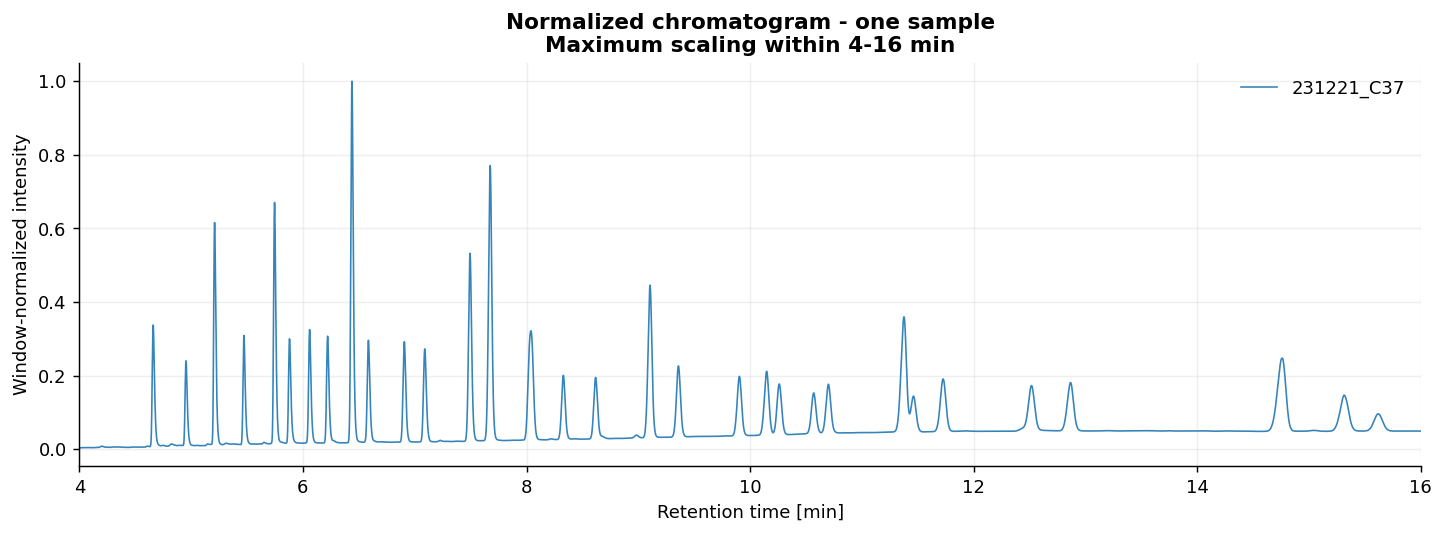

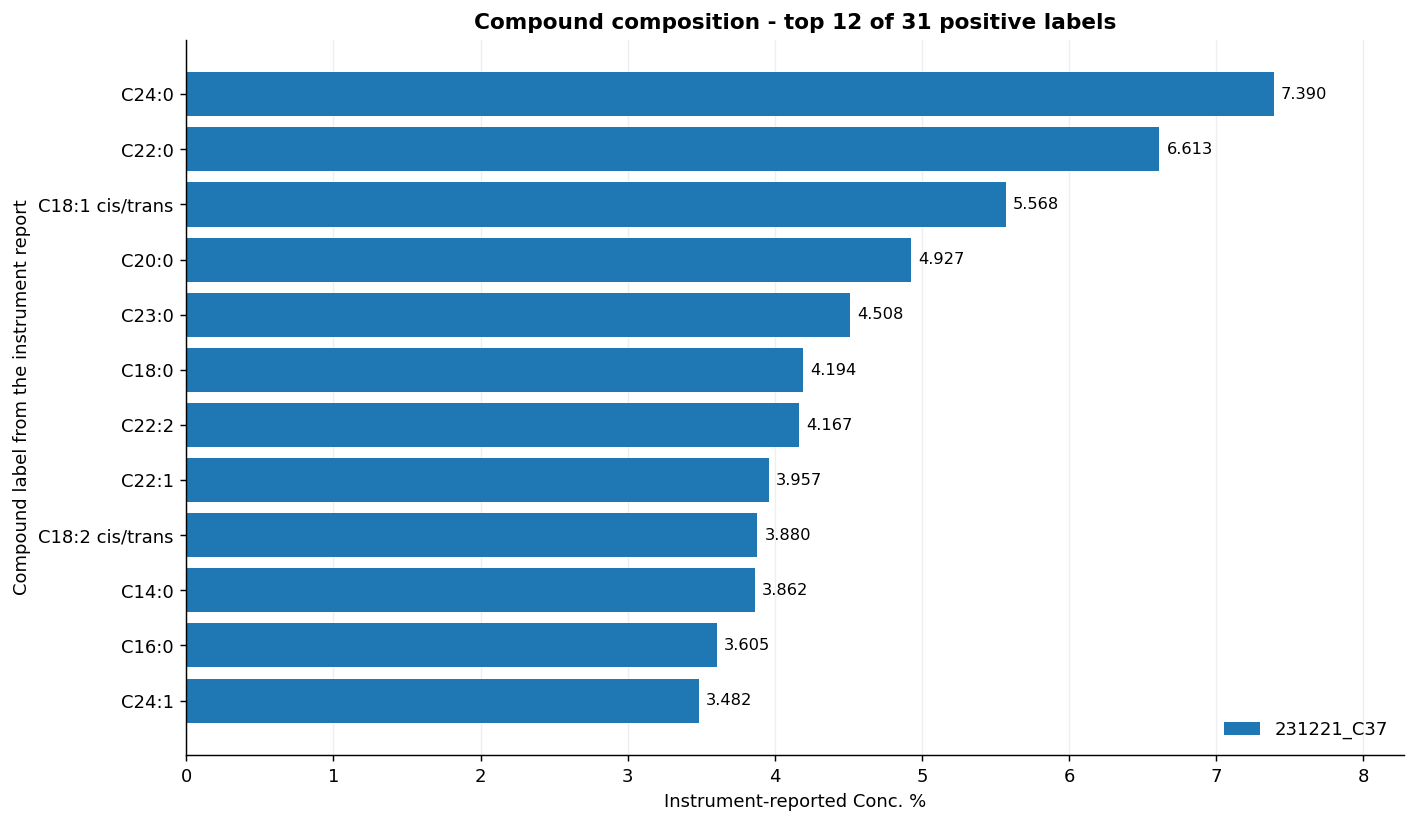

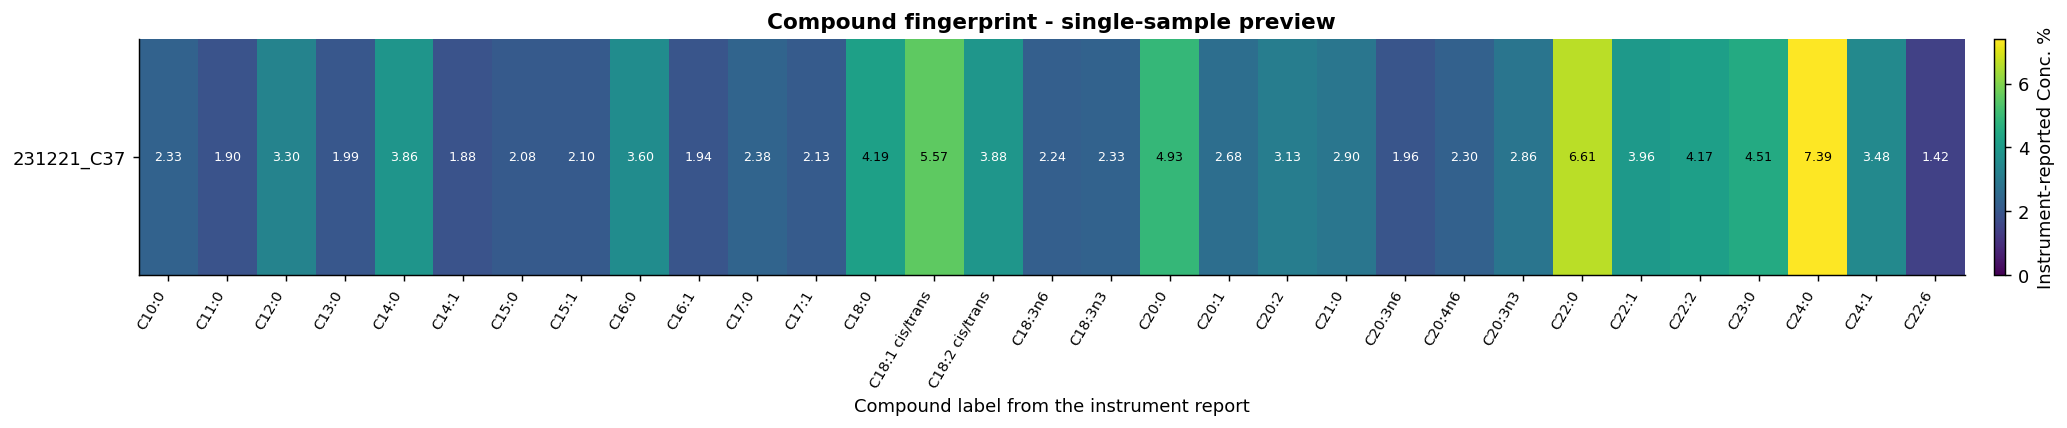

In [11]:
samples = load_samples(SAMPLE_FILES, ENCODING, SECTION, COMPOUND_SECTION)
print(f"Real sample files loaded: {len(samples)}")
for label, sample in samples.items():
    records = sample["compounds"]
    positive = sum(row["reported_percent"] > 0 for row in records)
    total = sum(row["reported_percent"] for row in records)
    print(f"{label}: {len(records)} compound rows, {positive} positive percentages, reported sum = {total:.3f}%")
if len(samples) == 1:
    print("Single-sample previews: add real reference files in SAMPLE_FILES for comparisons.")

overlay_figure = plot_normalized_overlay(samples, NORMALIZATION_START, NORMALIZATION_END, FIGURE_SIZE)
sample_names, compound_names, compound_matrix, value_label = build_compound_matrix(samples, COMPOUND_METRIC)
bar_figure = plot_compound_bars(sample_names, compound_names, compound_matrix, value_label, TOP_COMPOUNDS)
heatmap_figure = plot_compound_heatmap(sample_names, compound_names, compound_matrix, value_label, ANNOTATE_HEATMAP)

if SAVE_PLOTS:
    OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    overlay_figure.savefig(OUTPUT_DIRECTORY / OVERLAY_PLOT_FILENAME, dpi=DPI)
    bar_figure.savefig(OUTPUT_DIRECTORY / BAR_PLOT_FILENAME, dpi=DPI)
    heatmap_figure.savefig(OUTPUT_DIRECTORY / HEATMAP_PLOT_FILENAME, dpi=DPI)
plt.show()


## Scientific interpretation

- Matching retention times under the same analytical conditions can support a candidate identification. Coeluting compounds can share a retention time, so visual agreement alone does not establish identity.
- Peak area provides a quantitative signal, but response factors and calibration affect its conversion to concentration. Maximum-normalized intensity and uncorrected area percentages have different meanings.
- The file includes linear calibration coefficients. This notebook displays the exported `Conc. %` values; it does not independently validate those coefficients.
- Compound percentages and oil mixing fractions are different quantities. Estimating a two-oil mixture requires compatible reference profiles and a justified quantitative model.

Source: [Shimadzu — Analysis results of GC](https://www.shimadzu.eu/service-support/technical-support/analysis-basics/fundamentals/results.html).


## 12. Validate data and create a detection copy

The original arrays are copied and preserved, including negative intensities.
Time must increase strictly, and the sample spacing must be nearly uniform.
The export rounds time to five decimal places; a 5% interval tolerance accommodates
that rounding. Irregular sampling needs explicit resampling rather than a silent change.

Savitzky-Golay smoothing is applied only to a separate detection copy. Baseline subtraction
and the exported corrected signal use the unsmoothed measurements. The requested time
window is converted to an odd number of samples.

The noise diagnostic uses the median absolute deviation of adjacent differences, divided
by `0.67448975 * sqrt(2)`. It estimates high-frequency noise under approximately independent
noise assumptions. Correlation or slow background variations can make this estimate too low.

In [12]:
def validate_signal(retention_time, intensity, relative_tolerance):
    """Validate signed data and the nearly uniform sampling used by the filters."""
    if not np.isfinite(relative_tolerance) or relative_tolerance < 0:
        raise ValueError("The sampling tolerance must be finite and nonnegative.")
    time = np.asarray(retention_time, dtype=float)
    signal = np.asarray(intensity, dtype=float)
    if time.ndim != 1 or time.shape != signal.shape or time.size < 7:
        raise ValueError("Time and intensity must be matching 1D arrays with at least 7 points.")
    if not np.isfinite(time).all() or not np.isfinite(signal).all():
        raise ValueError("Non-finite measurements need explicit review before preprocessing.")
    intervals = np.diff(time)
    if np.any(intervals <= 0):
        raise ValueError("Retention times must be strictly increasing.")
    interval = float((time[-1] - time[0]) / (time.size - 1))
    relative_error = float(np.max(np.abs(intervals - interval)) / interval)
    if relative_error > relative_tolerance:
        raise ValueError("Sampling is irregular. Resample explicitly before using these filters.")
    return time.copy(), signal.copy(), interval


def smooth_for_detection(signal, interval_min, window_min, polynomial_order):
    """Smooth a separate detection copy; do not replace the measured signal."""
    if window_min <= 0 or polynomial_order < 0:
        raise ValueError("The smoothing window must be positive and the order nonnegative.")
    window = max(int(round(window_min / interval_min)), polynomial_order + 2)
    if window % 2 == 0:
        window += 1
    if window > len(signal):
        raise ValueError("The smoothing window exceeds the selected data length.")
    return savgol_filter(signal, window_length=window, polyorder=polynomial_order), window


def estimate_noise_sigma(signal, floor):
    """Estimate high-frequency noise using the MAD of first differences."""
    differences = np.diff(np.asarray(signal, dtype=float))
    if differences.size == 0 or floor <= 0:
        raise ValueError("Noise estimation requires data and a positive noise floor.")
    mad = np.median(np.abs(differences - np.median(differences)))
    sigma = float(mad / (0.6744897501960817 * np.sqrt(2)))
    return max(sigma, float(floor))

## 13. Locate the dominant early-peak candidate

The algorithm searches before `early_search_end_min` and requires a large prominence.
It also requires that the prominence exceed the later signal reference by the configured
dominance factor. An early peak that fails either condition is not excluded.

The raw apex is located near the smoothed maximum. This locates an early-peak candidate;
chromatogram shape alone does not establish that it is a solvent peak.

The return threshold is

$$T = b_{\mathrm{ref}} + \max\left(a_{\mathrm{min}},\ k\sigma_{\mathrm{ref}},\ fP\right),$$

where the reference level is the median in the configured quiet interval, `P` is the
candidate prominence, and `f`, `k`, and the absolute minimum margin are adjustable settings.
The smoothed signal must remain below `T` for the complete hold interval. The proposed
analysis start follows the confirmed return interval plus the configured padding.

This is an operational definition of tail recovery, not a chemically exact peak endpoint.
The reference interval is an assumption to check in the plot.

In [13]:
def detect_solvent_candidate(time, raw_signal, interval_min, settings):
    """Locate a dominant early peak and a sustained return to a reference level.

    The result is an operational early-peak candidate, not chemical identification.
    The configured background interval must be a suitable quiet reference region.
    """
    record = {"found": False, "recovered": False, "reason": "Detection disabled."}
    if not settings["detect_early_peak"]:
        return record
    search_end = float(settings["early_search_end_min"])
    early_indices = np.flatnonzero(time <= search_end)
    later_indices = np.flatnonzero(time > search_end)
    if len(early_indices) < 7 or len(later_indices) < 7:
        record["reason"] = "Not enough data before and after the early search limit. No points excluded."
        return record
    background_start, background_end = settings["background_interval_min"]
    if not time[0] <= background_start < background_end <= search_end:
        raise ValueError("The background interval must lie within the early search region.")
    reference_mask = (time >= background_start) & (time <= background_end)
    reference = raw_signal[reference_mask]
    if len(reference) < 7:
        raise ValueError("The background reference contains too few measurements.")
    smooth, window = smooth_for_detection(
        raw_signal[early_indices], interval_min,
        settings["smooth_window_min"], settings["smooth_polyorder"],
    )
    local_peaks, properties = find_peaks(
        smooth, prominence=settings["min_early_prominence"],
    )
    if len(local_peaks) == 0:
        record["reason"] = "No early peak meets the prominence threshold. No points excluded."
        return record
    candidate_number = int(np.argmax(properties["prominences"]))
    local_index = int(local_peaks[candidate_number])
    prominence = float(properties["prominences"][candidate_number])
    background_level = float(np.median(reference))
    noise_sigma = estimate_noise_sigma(reference, settings["noise_floor"])
    later_scale = max(
        float(np.percentile(raw_signal[later_indices], 99.5)) - background_level,
        noise_sigma,
    )
    dominance = prominence / later_scale
    if dominance < settings["min_early_dominance"]:
        record["reason"] = "The early peak does not dominate later signals sufficiently. No points excluded."
        return record
    # Refine the apex against the raw data in the smoothing window.
    half_window = window // 2
    left = max(0, local_index - half_window)
    right = min(len(early_indices), local_index + half_window + 1)
    local_index = left + int(np.argmax(raw_signal[early_indices[left:right]]))
    peak_index = int(early_indices[local_index])
    record.update({
        "found": True,
        "peak_index": peak_index,
        "peak_time_min": float(time[peak_index]),
        "peak_intensity_raw": float(raw_signal[peak_index]),
        "prominence_smoothed": prominence,
        "dominance_over_later_reference": float(dominance),
        "background_level_raw": background_level,
        "background_noise_sigma": noise_sigma,
        "background_interval_min": [float(background_start), float(background_end)],
    })
    if background_start <= time[peak_index]:
        raise ValueError("The quiet reference must follow the candidate apex. Adjust the settings.")
    return_margin = max(
        settings["return_absolute_margin"],
        settings["return_noise_factor"] * noise_sigma,
        settings["return_fraction_of_prominence"] * prominence,
    )
    threshold = background_level + return_margin
    full_smooth, _ = smooth_for_detection(
        raw_signal, interval_min, settings["smooth_window_min"], settings["smooth_polyorder"],
    )
    hold_points = max(2, int(np.ceil(settings["return_hold_min"] / interval_min)))
    below = full_smooth <= threshold
    cumulative = np.r_[0, np.cumsum(below, dtype=np.int64)]
    stable_starts = np.flatnonzero(
        cumulative[hold_points:] - cumulative[:-hold_points] == hold_points
    )
    stable_starts = stable_starts[stable_starts > peak_index]
    record["return_threshold_raw"] = float(threshold)
    if len(stable_starts) == 0:
        record["reason"] = "The candidate tail never meets the sustained-return criterion."
        return record
    recovery_start_index = int(stable_starts[0])
    confirmed_index = recovery_start_index + hold_points - 1
    proposed_start = float(time[confirmed_index] + settings["post_recovery_padding_min"])
    record.update({
        "recovered": True,
        "recovery_start_min": float(time[recovery_start_index]),
        "recovery_confirmed_min": float(time[confirmed_index]),
        "analysis_start_suggested_min": proposed_start,
        "reason": "Dominant early candidate followed by a sustained return below the configured threshold.",
    })
    return record


## 14. Select the analysis region

The selected region is represented by a Boolean mask. All original points remain available.
`analysis_start_min=None` uses the confirmed early-peak recovery. A numeric value overrides
that decision. If no dominant candidate is found, the full trace is retained.

If a dominant candidate is found but never meets the return criterion, automatic selection
stops with a clear error. An explicit start can be set after reviewing the trace.
The display window in the original charts does not determine this analysis mask.

In [14]:
def select_analysis_region(time, candidate, settings):
    """Choose a mask without removing any points from the original arrays."""
    manual_start = settings["analysis_start_min"]
    if manual_start is not None:
        start = float(manual_start)
        start_source = "manual"
    elif candidate["found"]:
        if not candidate["recovered"]:
            raise ValueError(
                "The early candidate has no validated return interval. "
                "Set analysis_start_min explicitly after inspecting the trace."
            )
        start = candidate["analysis_start_suggested_min"]
        start_source = "sustained early-peak recovery plus padding"
    else:
        start = float(time[0])
        start_source = "full trace: no dominant early candidate"
    end = float(time[-1]) if settings["analysis_end_min"] is None else float(settings["analysis_end_min"])
    if not np.isfinite(start) or not np.isfinite(end) or start >= end:
        raise ValueError("The selected analysis start must precede its end.")
    mask = (time >= start) & (time <= end)
    if np.count_nonzero(mask) < 7:
        raise ValueError("The selected analysis region contains too few measurements.")
    return mask, {"requested_start_min": start, "requested_end_min": end, "start_source": start_source}


## 15. Select baseline points and fit a polynomial

In polynomial mode, selected measured points determine the baseline. Automatic selection
keeps low-signal values within successive time bins. Manual selection uses configured time
intervals and/or the nearest measurements to specified anchor times. These points must
represent background outside peaks; the automatic candidates need inspection.

The configured degree is fixed before fitting. The code calls `np.polyfit` on the selected
points, then `np.polyval` at every selected analysis time. Time is centered and scaled to
reduce numerical conditioning problems:

$$u=\frac{t-t_{\mathrm{center}}}{t_{\mathrm{scale}}},\qquad b(t)=\operatorname{polyval}(a,u).$$

Coefficients are stored in descending powers of `u`, along with the time transformation.
This still represents a polynomial in time; the stored coefficients are not coefficients
in unscaled minutes. The fit rank and selected-point RMSE are reported. Extrapolated points
outside the selected background-point span are counted.

The least-squares fit minimizes error for the chosen degree and chosen points. It does not
automatically find the correct physical background. Increasing degree can improve selected-
point fit while also creating oscillations. A cubic model may underfit curved background
features in this real export; the diagnostic displays that limitation instead of hiding it.

The earlier asymmetric least-squares estimator remains an optional alternative. Its settings
apply only when `baseline_method="asls"`.

References: [NumPy polyfit](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html)
and [NumPy polyval](https://numpy.org/doc/stable/reference/generated/numpy.polyval.html).

In [15]:
def select_baseline_points(time, signal, settings):
    """Select candidate background points automatically or from manual regions."""
    selection = settings["baseline_point_selection"]
    mask = np.zeros(len(time), dtype=bool)
    if selection == "automatic":
        width = float(settings["baseline_bin_width_min"])
        quantile = float(settings["baseline_low_quantile"])
        if width <= 0 or not 0 < quantile <= 0.5:
            raise ValueError("Use a positive baseline bin width and a quantile in (0, 0.5].")
        bins = np.floor((time - time[0]) / width).astype(int)
        for number in np.unique(bins):
            indices = np.flatnonzero(bins == number)
            threshold = np.quantile(signal[indices], quantile)
            mask[indices[signal[indices] <= threshold]] = True
        description = "Low-signal candidate points in consecutive time bins."
    elif selection == "manual":
        intervals = settings["baseline_intervals_min"]
        anchors = settings["baseline_anchor_times_min"]
        if not intervals and not anchors:
            raise ValueError("Manual selection needs baseline intervals or anchor times.")
        for start, end in intervals:
            if not np.isfinite(start) or not np.isfinite(end) or start >= end:
                raise ValueError("Each baseline interval needs a finite start smaller than its end.")
            mask |= (time >= start) & (time <= end)
        for anchor in anchors:
            if not np.isfinite(anchor) or not time[0] <= anchor <= time[-1]:
                raise ValueError("Baseline anchor times must lie within the analysis region.")
            mask[int(np.argmin(np.abs(time - anchor)))] = True
        description = "Measured points inside manual intervals and nearest to manual anchors."
    else:
        raise ValueError("baseline_point_selection must be 'automatic' or 'manual'.")
    if not mask.any():
        raise ValueError("No baseline points were selected inside the analysis region.")
    return mask, {"point_selection": selection, "selection_description": description}


def estimate_polynomial_baseline(time, signal, point_mask, degree):
    """Use np.polyfit on selected points and np.polyval across the selected trace."""
    if isinstance(degree, bool) or not isinstance(degree, (int, np.integer)) or degree < 0:
        raise ValueError("The polynomial degree must be a nonnegative integer.")
    count = int(np.count_nonzero(point_mask))
    if count <= degree + 1:
        raise ValueError("Choose more baseline points than polynomial coefficients.")
    # Center and scale time to reduce the conditioning problems of polynomial fits.
    center = float((time[0] + time[-1]) / 2)
    scale = float((time[-1] - time[0]) / 2)
    if scale <= 0:
        raise ValueError("Polynomial fitting requires a nonzero time span.")
    scaled_time = (time - center) / scale
    coefficients, residuals, rank, singular_values, rcond = np.polyfit(
        scaled_time[point_mask], signal[point_mask], deg=degree, full=True,
    )
    if rank < degree + 1:
        raise ValueError("The polynomial fit is rank deficient. Review degree and selected points.")
    baseline = np.polyval(coefficients, scaled_time)
    if not np.isfinite(baseline).all():
        raise ValueError("The polynomial baseline contains non-finite values.")
    selected_residuals = signal[point_mask] - baseline[point_mask]
    first_point = float(time[point_mask][0])
    last_point = float(time[point_mask][-1])
    return baseline, {
        "method": "polynomial: np.polyfit and np.polyval",
        "degree": int(degree), "selected_point_count": count,
        "coefficients_highest_power_first": coefficients.tolist(),
        "time_center_min": center, "time_scale_min": scale,
        "coefficient_coordinate": "u = (retention_time_min - time_center_min) / time_scale_min",
        "selected_point_rmse": float(np.sqrt(np.mean(selected_residuals ** 2))),
        "selected_point_mean_residual": float(np.mean(selected_residuals)),
        "rank": int(rank),
        "scaled_vandermonde_condition_ratio": float(singular_values[0] / singular_values[-1]),
        "first_fit_point_min": first_point, "last_fit_point_min": last_point,
        "left_extrapolated_point_count": int(np.count_nonzero(time < first_point)),
        "right_extrapolated_point_count": int(np.count_nonzero(time > last_point)),
        "converged": True,
        "interpretation": (
            "The polynomial minimizes squared error for the chosen degree and selected points. "
            "The selected-point RMSE does not validate a physical baseline or select an optimal degree. "
            "Automatic low-signal selection can be biased by peaks or broad background features."
        ),
    }


def estimate_asls_baseline(signal, penalty, asymmetry, max_iterations, tolerance):
    """Fit an asymmetric least-squares baseline with a second-difference penalty.

    Large positive residuals have weight p; other residuals have weight 1-p.
    The baseline is an estimate for positive peaks on a smooth background.
    """
    signal = np.asarray(signal, dtype=float)
    if penalty <= 0 or not 0 < asymmetry < 0.5 or max_iterations < 2 or tolerance <= 0:
        raise ValueError("Use lambda > 0, 0 < p < 0.5, at least 2 iterations, and tolerance > 0.")
    size = len(signal)
    if size < 3 or not np.isfinite(signal).all():
        raise ValueError("Baseline fitting requires at least 3 finite measurements.")
    differences = sparse.diags(
        [np.ones(size - 2), -2 * np.ones(size - 2), np.ones(size - 2)],
        offsets=[0, 1, 2], shape=(size - 2, size), format="csc",
    )
    roughness = penalty * (differences.T @ differences)
    offset = float(np.median(signal))
    scale = max(float(np.max(np.abs(signal - offset))), 1.0)
    target = (signal - offset) / scale
    weights = np.ones(size)
    previous = None
    converged = False
    relative_change = None
    for iteration in range(1, max_iterations + 1):
        system = sparse.diags(weights, format="csc") + roughness
        solution = spsolve(system, weights * target)
        if not np.isfinite(solution).all():
            raise ValueError("The baseline solver produced non-finite values.")
        next_weights = np.where(target > solution, asymmetry, 1 - asymmetry)
        if previous is not None:
            relative_change = float(
                np.linalg.norm(solution - previous) / max(np.linalg.norm(previous), 1e-12)
            )
            if np.array_equal(next_weights, weights) or relative_change < tolerance:
                converged = True
                break
        previous = solution
        weights = next_weights
    baseline = offset + scale * solution
    return baseline, {
        "method": "asymmetric least squares, second differences",
        "lambda": float(penalty), "p": float(asymmetry),
        "iterations": iteration, "converged": converged,
        "relative_change": relative_change,
    }

## 16. Subtract the baseline and inspect negative values

The corrected signal is

$$y_{\mathrm{corrected}}(t)=y_{\mathrm{raw}}(t)-b(t).$$

Negative values are retained before and after subtraction. Taking `abs(y)` would reflect
negative noise into positive signal and alter peak heights and areas. Clipping to zero
would also alter subsequent area estimates.

Report the counts in the complete raw trace, selected raw trace, and corrected trace.
Values below the configurable negative inspection limit are flags for review only.
They may reflect noise, correlated background fluctuations, baseline mismatch, or a
negative signal. The code does not automatically classify or discard them.

A polynomial fitted to selected background candidates does not force every quiet region
to exactly zero. Remaining systematic residuals indicate limitations of the selected points
or baseline model and affect quantitative peak areas.

In [16]:
def inspect_negative_values(raw_full, raw_selected, corrected, settings):
    """Report signed negatives without rectification, clipping, or deletion."""
    sigma = estimate_noise_sigma(corrected, settings["noise_floor"])
    inspection_limit = settings["negative_sigma_factor"] * sigma
    return {
        "raw_full_negative_count": int(np.count_nonzero(raw_full < 0)),
        "raw_selected_negative_count": int(np.count_nonzero(raw_selected < 0)),
        "corrected_negative_count": int(np.count_nonzero(corrected < 0)),
        "corrected_below_inspection_limit_count": int(np.count_nonzero(corrected < -inspection_limit)),
        "minimum_corrected_intensity": float(np.min(corrected)),
        "high_frequency_noise_sigma": sigma,
        "negative_inspection_limit": float(-inspection_limit),
        "policy": "preserve signed values",
        "interpretation": (
            "The noise estimate uses adjacent differences and can be low for correlated data. "
            "Values below the limit are inspection flags, not evidence of absence or automatic errors. "
            "Slow background deviations and genuine negative signals also contribute."
        ),
    }


## 17. Detect initial peaks before assigning integration regions

`find_peaks` searches a smoothed copy of the signed corrected signal. Prominence, height,
minimum distance, and minimum width control the candidate search. The original and corrected
unsmoothed measurements remain unchanged.

Detection must precede per-peak boundary assignment: a peak maximum and neighboring maxima
are needed to choose its region. The half-prominence widths are shape descriptors; their
endpoints are not reused as full integration limits.

Candidate count can differ from the instrument table because the region, algorithm, and
thresholds differ. Signal candidates are numbered and are not assigned compound names.

In [17]:
def detect_corrected_peaks(time, corrected, smoothed, interval_min, noise_sigma, settings):
    """Find independent signal candidates; do not assign chemical names."""
    prominence_limit = max(settings["peak_min_prominence"], settings["peak_noise_factor"] * noise_sigma)
    distance_points = max(1, int(np.ceil(settings["peak_min_distance_min"] / interval_min)))
    width_points = settings["peak_min_width_min"] / interval_min
    peaks, properties = find_peaks(
        smoothed, prominence=prominence_limit,
        height=prominence_limit, distance=distance_points, width=width_points,
    )
    records = []
    indices = np.arange(len(time), dtype=float)
    for number, peak in enumerate(peaks, start=1):
        item = number - 1
        left = float(np.interp(properties["left_ips"][item], indices, time))
        right = float(np.interp(properties["right_ips"][item], indices, time))
        records.append({
            "peak_number": number,
            "time_max_smoothed_min": float(time[peak]),
            "corrected_intensity_at_detected_max": float(corrected[peak]),
            "smoothed_detection_height": float(smoothed[peak]),
            "prominence_smoothed": float(properties["prominences"][item]),
            "width_half_prominence_min": right - left,
            "left_half_prominence_min": left,
            "right_half_prominence_min": right,
        })
    return peaks, records, float(prominence_limit)


## 18. Assign disjoint integration regions and calculate signed areas

For each neighboring pair, locate the minimum of the smoothed corrected trace between their
maxima. This minimum caps the right region of the left peak and the left region of the right
peak. The resulting regions cannot share a time interval.

Within those caps, search outward from each maximum for a return below an operational level:
the larger of a small apex-height fraction and a multiple of the noise estimate. Crossing
times are interpolated. If no crossing exists before the cap, use the minimum or trace edge
as the boundary and flag it for review. The code verifies

$$t_{e,i}\le t_{s,i+1}.$$

When both neighboring regions reach their common cap, they share the same endpoint. An
endpoint has zero time width, so it does not contribute a duplicated area. Well-separated
peaks can instead have a gap between their return boundaries.

Integrate the signed, unsmoothed corrected signal between `integration_start_min` and
`integration_end_min`; insert interpolated endpoint samples when needed. No absolute values
or clipping are applied. The default uses the trapezoidal rule; Simpson's rule is separately
available. Areas in signal*minute and signal*second represent the same area in different units.

An elevated inter-peak valley is flagged by its height relative to the smaller neighboring
apex. This is a review heuristic, not proof of coelution. Numerical valley partitioning prevents
double counting; it does not recover the true areas of strongly overlapping components. Such
rows remain marked, and curve fitting/deconvolution is a subsequent analysis step. Unresolved
shoulders may not produce two detected maxima at all.

References: [SciPy trapezoid](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.trapezoid.html)
and [SciPy simpson](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.simpson.html).

In [18]:
def define_integration_regions(time, smoothed, peak_indices, noise_sigma, settings):
    """Set operational peak boundaries inside non-overlapping valley partitions."""
    peaks = np.asarray(peak_indices, dtype=int)
    if len(peaks) == 0:
        return [], []
    if np.any(np.diff(peaks) < 2) or peaks[0] <= 0 or peaks[-1] >= len(time) - 1:
        raise ValueError("Integration requires ordered interior maxima with a separating sample.")
    fraction = float(settings["boundary_relative_height"])
    if not 0 < fraction < 0.5 or settings["boundary_noise_factor"] <= 0:
        raise ValueError("Use a boundary fraction in (0, 0.5) and a positive noise factor.")
    overlap_limit = float(settings["overlap_valley_fraction"])
    if not 0 < overlap_limit < 1:
        raise ValueError("The overlap review fraction must be in (0, 1).")
    valleys = []
    overlap_flags = np.zeros(len(peaks), dtype=bool)
    for number, (left_peak, right_peak) in enumerate(zip(peaks[:-1], peaks[1:])):
        valley = int(left_peak + 1 + np.argmin(smoothed[left_peak + 1:right_peak]))
        lower_apex = min(float(smoothed[left_peak]), float(smoothed[right_peak]))
        ratio = max(float(smoothed[valley]), 0) / max(lower_apex, 1e-12)
        review = bool(ratio >= overlap_limit)
        if review:
            overlap_flags[number:number + 2] = True
        valleys.append({
            "left_peak_number": number + 1, "right_peak_number": number + 2,
            "index": valley, "time_min": float(time[valley]),
            "valley_fraction_of_smaller_apex": float(ratio),
            "overlap_review_required": review,
        })

    def crossing_time(first, second, threshold):
        y_first, y_second = float(smoothed[first]), float(smoothed[second])
        if y_second == y_first:
            return float(time[first])
        relative = np.clip((threshold - y_first) / (y_second - y_first), 0, 1)
        return float(time[first] + relative * (time[second] - time[first]))

    records = []
    for number, peak in enumerate(peaks):
        left_limit = 0 if number == 0 else valleys[number - 1]["index"]
        right_limit = len(time) - 1 if number == len(peaks) - 1 else valleys[number]["index"]
        threshold = max(
            fraction * float(smoothed[peak]),
            settings["boundary_noise_factor"] * noise_sigma,
        )
        left_returns = np.flatnonzero(smoothed[left_limit:peak] <= threshold)
        right_returns = np.flatnonzero(smoothed[peak + 1:right_limit + 1] <= threshold)
        left_found, right_found = bool(len(left_returns)), bool(len(right_returns))
        if left_found:
            below = int(left_limit + left_returns[-1])
            start = crossing_time(below, below + 1, threshold)
            left_method = "interpolated return threshold"
        else:
            start = float(time[left_limit])
            left_method = "trace edge" if number == 0 else "shared inter-peak minimum"
        if right_found:
            below = int(peak + 1 + right_returns[0])
            end = crossing_time(below - 1, below, threshold)
            right_method = "interpolated return threshold"
        else:
            end = float(time[right_limit])
            right_method = "trace edge" if number == len(peaks) - 1 else "shared inter-peak minimum"
        if not start < time[peak] < end:
            raise ValueError("An integration boundary does not bracket its peak maximum.")
        records.append({
            "peak_number": number + 1,
            "integration_start_min": start, "integration_end_min": end,
            "boundary_threshold_corrected": float(threshold),
            "left_boundary_method": left_method, "right_boundary_method": right_method,
            "left_return_found": left_found, "right_return_found": right_found,
            "overlap_review_required": bool(overlap_flags[number]),
            "boundary_review_required": bool(not left_found or not right_found),
        })
    for left, right in zip(records[:-1], records[1:]):
        if left["integration_end_min"] > right["integration_start_min"]:
            raise RuntimeError("Integration intervals overlap; this would count a time segment twice.")
    return records, valleys


def integrate_peak_regions(time, corrected, regions, method):
    """Integrate signed, unsmoothed data with interpolated interval endpoints."""
    if method not in {"trapezoid", "simpson"}:
        raise ValueError("integration_method must be 'trapezoid' or 'simpson'.")
    time, corrected = validate_chromatogram(time, corrected)
    results = []
    previous_end = None
    for region in regions:
        start, end = region["integration_start_min"], region["integration_end_min"]
        if (not np.isfinite(start) or not np.isfinite(end)
                or not time[0] <= start < end <= time[-1]
                or (previous_end is not None and start < previous_end)):
            raise ValueError("Integration regions must be finite, ordered, disjoint, and inside the data range.")
        previous_end = end
        interior = (time > start) & (time < end)
        interval_time = np.r_[start, time[interior], end]
        interval_signal = np.interp(interval_time, time, corrected)
        # A shared endpoint has zero time width; no interval is integrated twice.
        if method == "trapezoid":
            area_min = float(trapezoid(interval_signal, x=interval_time))
        else:
            area_min = float(simpson(interval_signal, x=interval_time))
        results.append({
            **region, "integration_method": method,
            "area_signal_min": area_min, "area_signal_s": area_min * 60,
            "integration_point_count": len(interval_time),
        })
    return results

## 19. Assemble the preprocessing and integration workflow

The order is: original data, early-peak candidate, selected region, background-point selection,
polynomial fit/evaluation, signed correction, negative-value inspection, candidate detection,
non-overlapping boundary assignment, and signed numerical integration.

The returned dictionary keeps each data stage separate. Instrument-reported compound
percentages are not recalculated from these new uncalibrated candidate areas.

In [19]:
def preprocess_chromatogram(retention_time, intensity, settings, run_peak_preview=True):
    """Prepare signed data, locate peaks, and integrate non-overlapping regions."""
    time_full, raw_full, interval = validate_signal(
        retention_time, intensity, settings["sampling_relative_tolerance"],
    )
    candidate = detect_solvent_candidate(time_full, raw_full, interval, settings)
    mask, selection = select_analysis_region(time_full, candidate, settings)
    time, raw_selected = time_full[mask], raw_full[mask]
    baseline_point_mask = np.zeros(len(time), dtype=bool)
    if settings["baseline_method"] == "polynomial":
        baseline_point_mask, selection_info = select_baseline_points(time, raw_selected, settings)
        baseline, baseline_info = estimate_polynomial_baseline(
            time, raw_selected, baseline_point_mask, settings["polynomial_degree"],
        )
        baseline_info.update(selection_info)
    elif settings["baseline_method"] == "asls":
        baseline, baseline_info = estimate_asls_baseline(
            raw_selected, settings["baseline_lambda"], settings["baseline_p"],
            settings["baseline_max_iterations"], settings["baseline_tolerance"],
        )
    else:
        raise ValueError("baseline_method must be 'polynomial' or 'asls'.")
    corrected = raw_selected - baseline
    negative_info = inspect_negative_values(raw_full, raw_selected, corrected, settings)
    smoothed, smoothing_points = smooth_for_detection(
        corrected, interval, settings["smooth_window_min"], settings["smooth_polyorder"],
    )
    if run_peak_preview:
        peaks, peak_records, prominence_limit = detect_corrected_peaks(
            time, corrected, smoothed, interval,
            negative_info["high_frequency_noise_sigma"], settings,
        )
        regions, valleys = define_integration_regions(
            time, smoothed, peaks, negative_info["high_frequency_noise_sigma"], settings,
        )
        integrations = integrate_peak_regions(time, corrected, regions, settings["integration_method"])
        integrated_records = [{**peak, **integration} for peak, integration in zip(peak_records, integrations)]
    else:
        peaks, peak_records, prominence_limit = np.array([], dtype=int), [], None
        regions, valleys, integrated_records = [], [], []
    summary = {
        "input_points": len(time_full), "analysis_points": len(time),
        "sampling_interval_min": interval,
        "first_selected_time_min": float(time[0]), "last_selected_time_min": float(time[-1]),
        "candidate": candidate, "selection": selection, "baseline": baseline_info,
        "negative_values": negative_info,
        "detection_smoothing_window_points": smoothing_points,
        "peak_preview_enabled": bool(run_peak_preview), "peak_candidate_count": len(peak_records),
        "peak_prominence_threshold": prominence_limit,
        "integration": {
            "method": settings["integration_method"], "regions_non_overlapping": True,
            "integrated_peak_count": len(integrated_records),
            "overlap_review_peak_count": sum(record["overlap_review_required"] for record in regions),
            "boundary_review_peak_count": sum(record["boundary_review_required"] for record in regions),
            "signed_total_area_signal_min": sum(record["area_signal_min"] for record in integrated_records),
            "signed_total_area_signal_s": sum(record["area_signal_s"] for record in integrated_records),
            "interpretation": "Valley partitioning prevents duplicate integration, but does not deconvolve overlapping components.",
        },
        "settings": deepcopy(settings),
        "units": "Time and widths: minutes. Areas: original signal unit times minutes or seconds. The physical signal unit is unspecified.",
        "notes": [
            "The early peak remains a candidate, not a confirmed solvent identity.",
            "The early recovery threshold and quiet reference are operational assumptions.",
            "The default polynomial is a least-squares fit to selected background candidates, not a validated optimal physical baseline.",
            "Signed residuals are preserved; smoothing is used only for detection and boundary search.",
            "Peak detection precedes per-peak integration-boundary assignment.",
            "Regions are disjoint in time; the unsmoothed signed signal is integrated once within each region.",
            "High inter-peak valleys are flagged for overlap review; their areas are not component-specific deconvolved areas.",
            "Instrument-reported compound percentages are not recalculated from these candidate areas.",
            "Curve fitting, chemical identification, and quantitative calibration are subsequent steps.",
        ],
    }
    return {
        "time_full": time_full, "raw_full": raw_full, "selection_mask": mask,
        "time": time, "raw_selected": raw_selected, "baseline": baseline,
        "baseline_point_mask": baseline_point_mask,
        "corrected": corrected, "smoothed": smoothed,
        "peak_indices": peaks, "peak_records": peak_records,
        "integration_records": integrated_records, "valleys": valleys, "summary": summary,
    }

## 20. Diagnostic plots and exports

Five new plots show early-peak recovery, selected baseline points and the fitted curve,
signed negatives near zero, numbered peak maxima, and shaded disjoint integration regions.
Orange integration regions require boundary or overlap review; green regions have detected
return boundaries without that flag. Color is not evidence of chemical identity or validated area.

The full signal CSV retains all original measurements and identifies points used in the
polynomial fit. Derived fields remain empty outside the selected analysis region. Separate
CSV files contain peak descriptors and integration boundaries, signed areas, and review flags.
The JSON stores method, polynomial coefficients/coordinate transformation, parameters, and decisions.

In [20]:
def plot_early_peak_selection(result, settings, figure_size):
    """Show the early apex and the operational tail-recovery criterion."""
    time, raw = result["time_full"], result["raw_full"]
    candidate = result["summary"]["candidate"]
    selected = time <= settings["early_search_end_min"]
    fig, axes = plt.subplots(2, 1, figsize=(figure_size[0], 7), sharex=True)
    for ax in axes:
        ax.plot(time[selected], raw[selected], color="#176B87", linewidth=0.9, label="Original signed signal")
        reference_start, reference_end = settings["background_interval_min"]
        ax.axvspan(reference_start, reference_end, color="#888888", alpha=0.12, label="Background reference interval")
        if candidate["found"]:
            ax.axvline(candidate["peak_time_min"], color="#B54925", linestyle="--", label="Candidate apex")
        if candidate.get("recovered"):
            ax.axvspan(candidate["recovery_start_min"], candidate["recovery_confirmed_min"], color="#58A65C", alpha=0.2, label="Sustained recovery interval")
        ax.axvline(result["summary"]["selection"]["requested_start_min"], color="#7A4495", linestyle=":", label="Analysis start")
        ax.set_ylabel("Raw intensity")
        ax.grid(alpha=0.2)
    axes[0].set_title("Dominant early-peak candidate and analysis-region selection")
    axes[0].legend(frameon=False, loc="upper right", fontsize=9)
    axes[1].set_yscale("symlog", linthresh=settings["return_absolute_margin"])
    axes[1].set_ylim(
        min(-settings["return_absolute_margin"], float(np.min(raw[selected])) - settings["return_absolute_margin"]),
        max(float(np.max(raw[selected])) * 1.2, settings["return_absolute_margin"]),
    )
    if candidate["found"]:
        axes[1].axhline(candidate["return_threshold_raw"], color="#555555", linestyle="--", label="Return threshold")
    axes[1].set_title("Tail detail on a symmetric logarithmic intensity scale")
    axes[1].set_xlabel("Retention time [min]")
    axes[1].legend(frameon=False, loc="upper right", fontsize=9)
    fig.tight_layout()
    return fig


def plot_baseline_correction(result, figure_size):
    """Display selected background points, fitted baseline, and signed residuals."""
    time, raw = result["time"], result["raw_selected"]
    baseline, corrected = result["baseline"], result["corrected"]
    points = result["baseline_point_mask"]
    method = result["summary"]["settings"]["baseline_method"]
    label = "Polynomial baseline" if method == "polynomial" else "AsLS baseline"
    fig, axes = plt.subplots(3, 1, figsize=(figure_size[0], 9), sharex=True)
    for ax in axes[:2]:
        ax.plot(time, raw, color="#176B87", linewidth=0.8, label="Raw signal")
        if points.any():
            ax.scatter(time[points], raw[points], s=5, color="#42935A", alpha=0.55, label="Selected baseline points", zorder=3)
        ax.plot(time, baseline, color="#CE6E21", linewidth=1.7, label=label)
        ax.legend(frameon=True, facecolor="white", framealpha=0.95, loc="upper left", fontsize=9)
    axes[0].set_title("Selected raw signal, background candidates, and baseline fit")
    span = max(float(np.ptp(baseline)), 100)
    axes[1].set_ylim(float(np.min(baseline)) - span * 0.08, float(np.max(baseline)) + span * 0.12)
    axes[1].set_title("Background detail: selected points and baseline-fit deviations")
    axes[2].plot(time, corrected, color="#176B87", linewidth=0.8, label="Unsmoothed signed corrected signal")
    axes[2].axhline(0, color="#555555", linewidth=0.8)
    axes[2].set_title("Baseline-corrected signal: signed values are preserved")
    axes[2].legend(frameon=True, facecolor="white", framealpha=0.95, loc="upper right", fontsize=9)
    axes[2].set_xlabel("Retention time [min]")
    for ax in axes:
        ax.set_ylabel("Intensity")
        ax.grid(alpha=0.2)
    fig.tight_layout()
    return fig


def plot_negative_value_inspection(result, figure_size):
    """Display negatives near zero rather than hiding them beneath the peak scale."""
    fig, axes = plt.subplots(2, 1, figsize=(figure_size[0], 6.5))
    info = result["summary"]["negative_values"]
    for ax, time, signal, title in [
        (axes[0], result["time_full"], result["raw_full"], "Original signed data: near-zero detail"),
        (axes[1], result["time"], result["corrected"], "After baseline subtraction: near-zero detail"),
    ]:
        negative = signal < 0
        ax.plot(time, signal, color="#176B87", linewidth=0.7, label="Signed signal")
        ax.scatter(time[negative], signal[negative], s=3, color="#B54925", label="Negative measurements")
        negatives = -signal[negative]
        magnitude = max(float(np.percentile(negatives, 98)) if len(negatives) else 0, 50)
        ax.set_ylim(-magnitude * 1.3, magnitude * 1.3)
        ax.axhline(0, color="#555555", linewidth=0.8)
        ax.set_title(title)
        ax.set_xlabel("Retention time [min]")
        ax.set_ylabel("Intensity")
        ax.grid(alpha=0.2)
        ax.legend(frameon=True, facecolor="white", framealpha=0.95, loc="upper right", fontsize=9)
    axes[1].axhline(info["negative_inspection_limit"], color="#7A4495", linestyle="--", linewidth=1, label="Inspection limit")
    axes[1].legend(frameon=True, facecolor="white", framealpha=0.95, loc="upper right", fontsize=9)
    fig.tight_layout()
    return fig


def plot_peak_preview(result, settings, figure_size):
    """Show numbered signal candidates without chemical assignments."""
    time, corrected = result["time"], result["corrected"]
    mask = (time >= settings["plot_start_min"]) & (time <= settings["plot_end_min"])
    if not mask.any():
        raise ValueError("The peak-preview plot range does not overlap the analysis region.")
    fig, ax = plt.subplots(figsize=(figure_size[0], 5))
    ax.plot(time[mask], corrected[mask], color="#176B87", linewidth=0.9, label="Unsmoothed corrected signal")
    peaks = result["peak_indices"]
    visible = (time[peaks] >= settings["plot_start_min"]) & (time[peaks] <= settings["plot_end_min"])
    ax.scatter(time[peaks[visible]], corrected[peaks[visible]], marker="x", s=28, color="#B54925", label="Detected candidates")
    for number, peak in enumerate(peaks, start=1):
        if settings["plot_start_min"] <= time[peak] <= settings["plot_end_min"]:
            ax.annotate(str(number), (time[peak], corrected[peak]), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=7)
    ax.axhline(0, color="#555555", linewidth=0.8)
    ax.set_xlabel("Retention time [min]")
    ax.set_ylabel("Signed corrected intensity")
    ax.set_title(f"Peak-search preview: {int(visible.sum())} candidates in the displayed window")
    ax.legend(frameon=False, loc="upper right", fontsize=9)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    return fig


def plot_integration_regions(result, settings, figure_size):
    """Show time partitions and flagged overlap without implying deconvolution."""
    time, corrected = result["time"], result["corrected"]
    visible = (time >= settings["plot_start_min"]) & (time <= settings["plot_end_min"])
    if not visible.any():
        raise ValueError("The integration display range does not overlap the analysis region.")
    fig, ax = plt.subplots(figsize=(figure_size[0], 5.5))
    ax.plot(time[visible], corrected[visible], color="#176B87", linewidth=0.9, label="Unsmoothed signed corrected signal")
    review_label_used = False
    regular_label_used = False
    for record in result["integration_records"]:
        start, end = record["integration_start_min"], record["integration_end_min"]
        if end < settings["plot_start_min"] or start > settings["plot_end_min"]:
            continue
        interior = (time > start) & (time < end)
        interval_time = np.r_[start, time[interior], end]
        signal = np.interp(interval_time, time, corrected)
        review = record["overlap_review_required"] or record["boundary_review_required"]
        if review:
            color = "#D48836"
            label = None if review_label_used else "Region requiring boundary/overlap review"
            review_label_used = True
        else:
            color = "#459D82"
            label = None if regular_label_used else "Region with detected return boundaries"
            regular_label_used = True
        ax.fill_between(interval_time, 0, signal, color=color, alpha=0.28, label=label)
        for boundary in [start, end]:
            if settings["plot_start_min"] <= boundary <= settings["plot_end_min"]:
                ax.axvline(boundary, color=color, linewidth=0.6, alpha=0.55)
    ax.set_xlim(settings["plot_start_min"], settings["plot_end_min"])
    ax.axhline(0, color="#555555", linewidth=0.8)
    ax.set_xlabel("Retention time [min]")
    ax.set_ylabel("Signed corrected intensity")
    ax.set_title("Disjoint integration regions: each time segment is counted at most once")
    ax.legend(frameon=True, facecolor="white", framealpha=0.95, loc="upper right", fontsize=9)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    return fig


def save_preprocessing_results(result, output_directory, prefix):
    """Export signed signal, background-point flags, peak regions, areas, and decisions."""
    output_directory = Path(output_directory)
    output_directory.mkdir(parents=True, exist_ok=True)
    mask = result["selection_mask"]
    baseline_full = np.full(len(mask), np.nan)
    corrected_full = np.full(len(mask), np.nan)
    smoothed_full = np.full(len(mask), np.nan)
    points_full = np.zeros(len(mask), dtype=bool)
    baseline_full[mask], corrected_full[mask], smoothed_full[mask] = result["baseline"], result["corrected"], result["smoothed"]
    points_full[mask] = result["baseline_point_mask"]
    signal_path = output_directory / f"{prefix}_signal.csv"
    with signal_path.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.writer(output_file)
        writer.writerow([
            "retention_time_min", "raw_intensity", "selected_for_analysis", "baseline_fit_point",
            "estimated_baseline", "corrected_intensity_signed", "smoothed_detection_signal",
        ])
        for index in range(len(mask)):
            values = [baseline_full[index], corrected_full[index], smoothed_full[index]]
            writer.writerow([
                float(result["time_full"][index]), float(result["raw_full"][index]), int(mask[index]), int(points_full[index]),
                *[float(value) if np.isfinite(value) else "" for value in values],
            ])
    fields = [
        "peak_number", "time_max_smoothed_min", "corrected_intensity_at_detected_max",
        "smoothed_detection_height", "prominence_smoothed", "width_half_prominence_min",
        "left_half_prominence_min", "right_half_prominence_min",
    ]
    peak_path = output_directory / f"{prefix}_peak_candidates.csv"
    with peak_path.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.DictWriter(output_file, fieldnames=fields)
        writer.writeheader()
        writer.writerows(result["peak_records"])
    integration_fields = [*fields,
        "integration_start_min", "integration_end_min", "boundary_threshold_corrected",
        "left_boundary_method", "right_boundary_method", "left_return_found", "right_return_found",
        "overlap_review_required", "boundary_review_required", "integration_method",
        "area_signal_min", "area_signal_s", "integration_point_count",
    ]
    integration_path = output_directory / f"{prefix}_integration.csv"
    with integration_path.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.DictWriter(output_file, fieldnames=integration_fields)
        writer.writeheader()
        writer.writerows(result["integration_records"])
    summary_path = output_directory / f"{prefix}_summary.json"
    summary_path.write_text(json.dumps(result["summary"], indent=2, allow_nan=False), encoding="utf-8")
    return [signal_path, peak_path, integration_path, summary_path]


def print_preprocessing_summary(result):
    """Print reviewable baseline and integration diagnostics."""
    summary = result["summary"]
    candidate = summary["candidate"]
    print(f"Original measurements: {summary['input_points']:,}")
    if candidate["found"]:
        print(f"Early candidate apex: {candidate['peak_time_min']:.5f} min")
        if candidate["recovered"]:
            print(f"Sustained return begins: {candidate['recovery_start_min']:.5f} min")
            print(f"Return confirmed at: {candidate['recovery_confirmed_min']:.5f} min")
        else:
            print(candidate["reason"])
    else:
        print(candidate["reason"])
    print(f"Selected region: {summary['first_selected_time_min']:.5f} to {summary['last_selected_time_min']:.5f} min")
    print(f"Selected measurements: {summary['analysis_points']:,}")
    baseline = summary["baseline"]
    if summary["settings"]["baseline_method"] == "polynomial":
        print(f"Polynomial baseline: degree {baseline['degree']}; selected points = {baseline['selected_point_count']:,}")
        print(f"Selected-point RMSE: {baseline['selected_point_rmse']:.3f} (diagnostic, not physical validation)")
        print(f"Coefficients in scaled time u: {baseline['coefficients_highest_power_first']}")
    else:
        print(f"AsLS baseline: {baseline['iterations']} iterations; converged = {baseline['converged']}")
    info = summary["negative_values"]
    print(f"Negative raw measurements, complete/selected: {info['raw_full_negative_count']:,} / {info['raw_selected_negative_count']:,}")
    print(f"Signed negative residuals after subtraction: {info['corrected_negative_count']:,}")
    print("Signed negatives and inspection flags are retained.")
    if summary["peak_preview_enabled"]:
        integration = summary["integration"]
        print(f"Independent peak candidates: {summary['peak_candidate_count']}")
        print(f"Integrated intervals: {integration['integrated_peak_count']}; non-overlapping = {integration['regions_non_overlapping']}")
        print(f"Overlap-review peaks: {integration['overlap_review_peak_count']}; boundary-review peaks: {integration['boundary_review_peak_count']}")
        print(f"Signed total candidate area: {integration['signed_total_area_signal_s']:.3f} signal*second")
        print("Valley partitioning prevents double counting; it does not separate coeluting components.")

## 21. Run the updated workflow

All settings are in the first code cell. `preprocessed["baseline_point_mask"]` identifies
the selected background candidates; `preprocessed["integration_records"]` contains starts,
ends, signed areas, and review flags. `preprocessed["raw_full"]` remains the complete raw signal.

The selected analysis start remains independent of a plot's display window.

Original measurements: 25,500
Early candidate apex: 1.70883 min
Sustained return begins: 2.50817 min
Return confirmed at: 2.58817 min
Selected region: 2.63817 to 16.99950 min
Selected measurements: 21,543
Polynomial baseline: degree 3; selected points = 3,385
Selected-point RMSE: 183.714 (diagnostic, not physical validation)
Coefficients in scaled time u: [-1497.8929573114428, -1792.9970411437837, 4389.502917685022, 4350.079683657836]
Negative raw measurements, complete/selected: 3,070 / 544
Signed negative residuals after subtraction: 7,191
Signed negatives and inspection flags are retained.
Independent peak candidates: 32
Integrated intervals: 32; non-overlapping = True
Overlap-review peaks: 2; boundary-review peaks: 9
Signed total candidate area: 2448720.035 signal*second
Valley partitioning prevents double counting; it does not separate coeluting components.
Saved: results/Gaschroma_preprocessing_signal.csv
Saved: results/Gaschroma_preprocessing_peak_candidates.csv
Saved: results/G

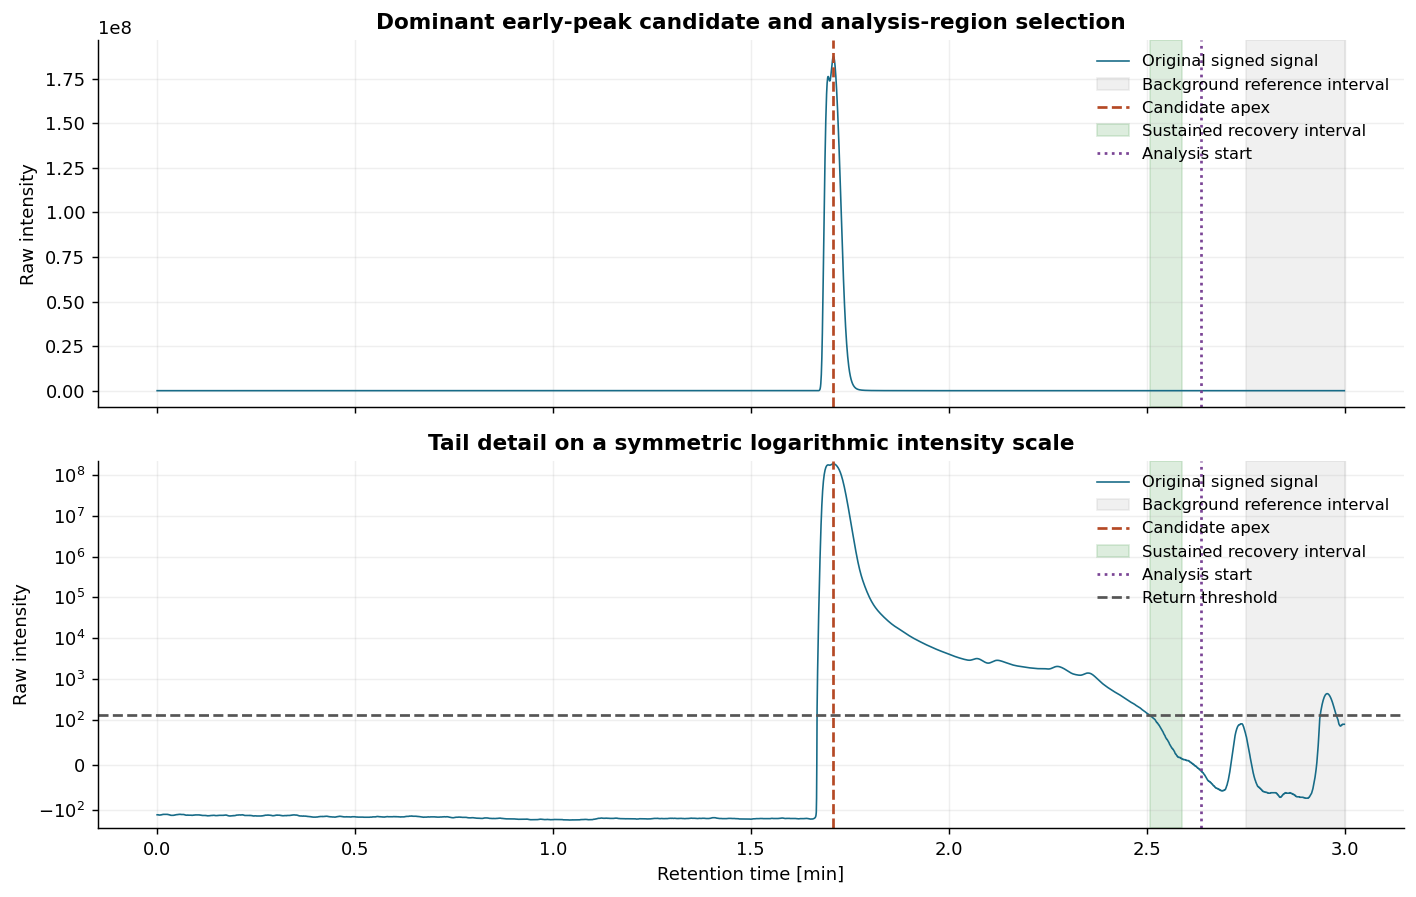

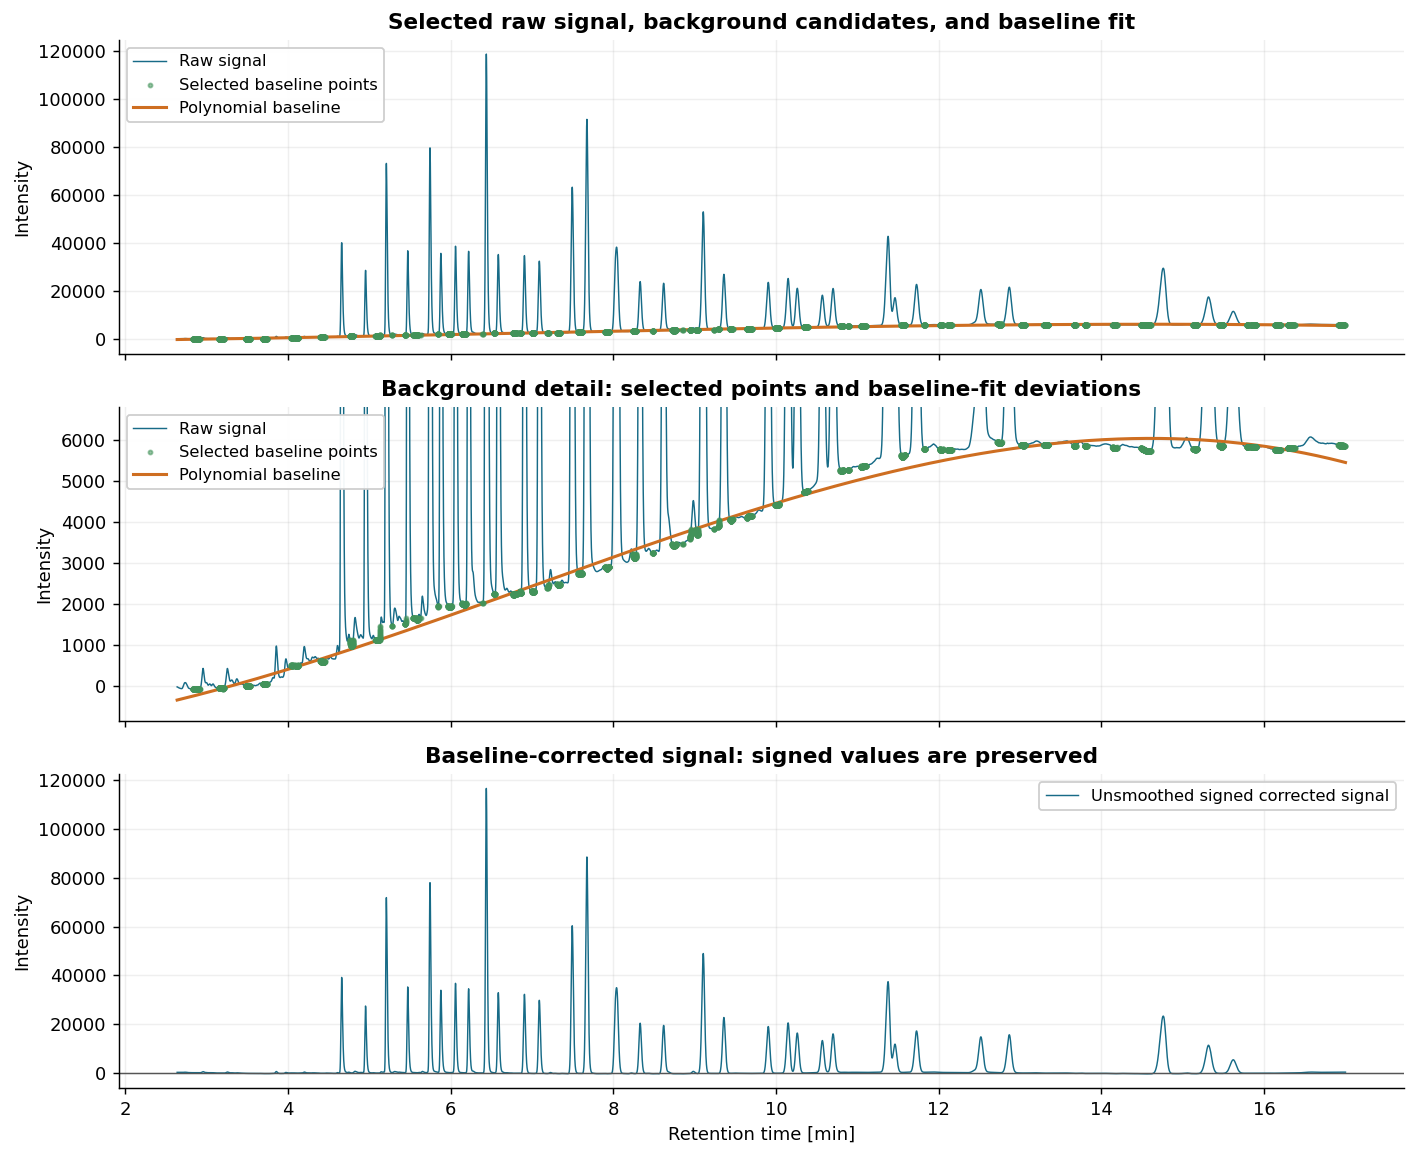

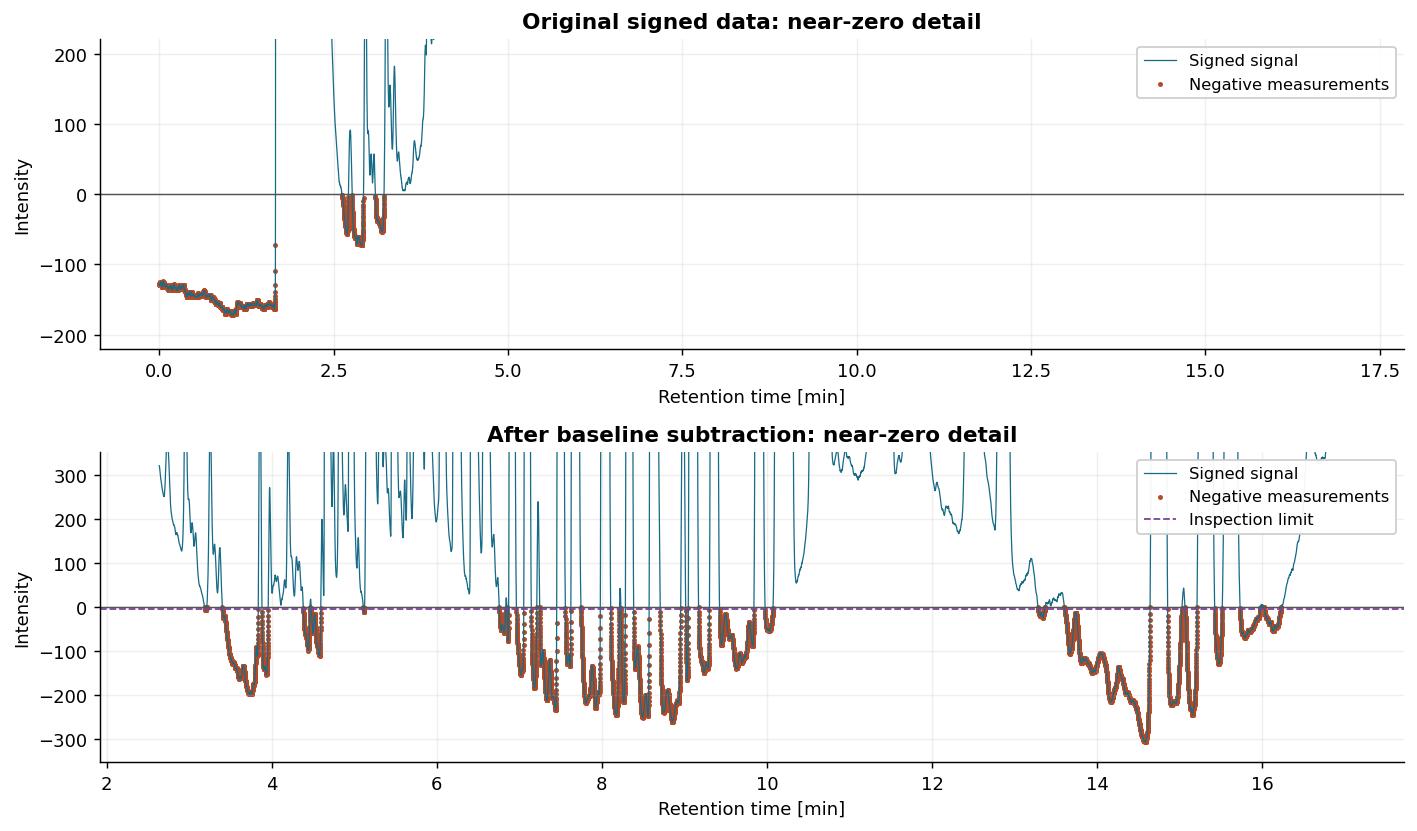

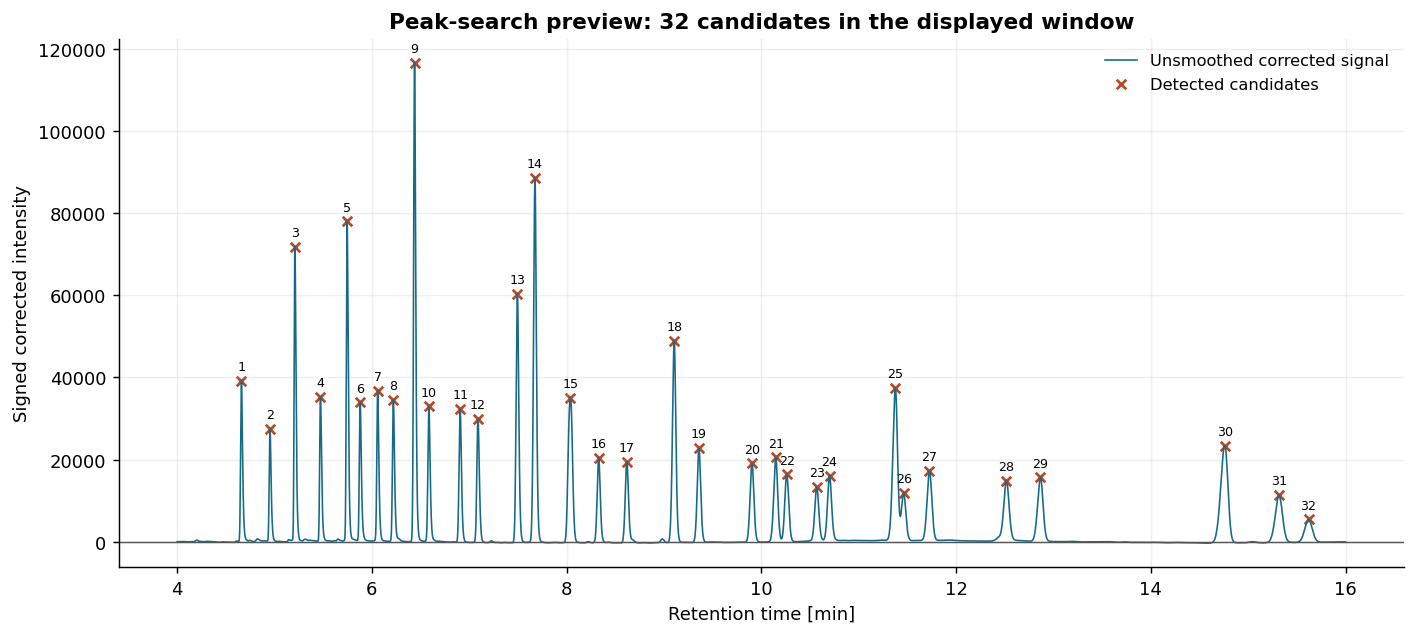

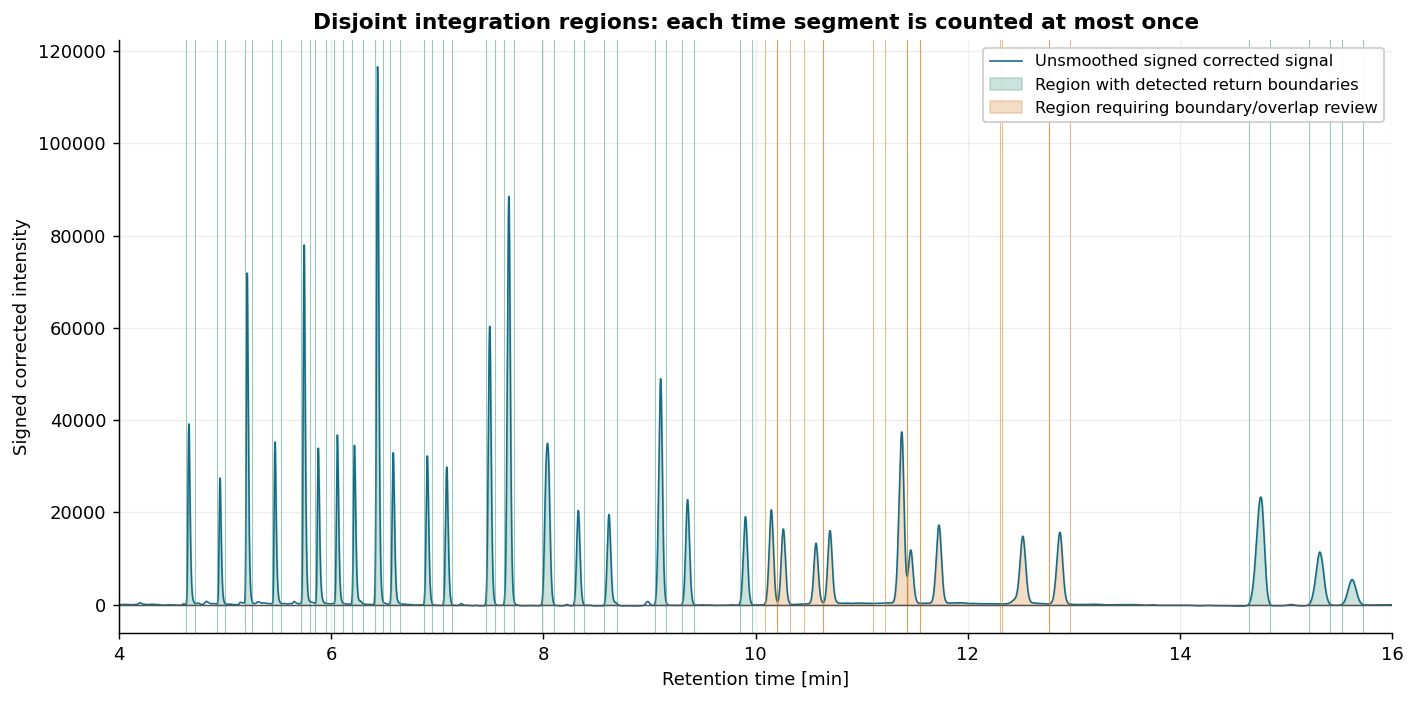

In [21]:
preprocessing_lines = read_file(INPUT_PATH, ENCODING)
preprocessing_time, preprocessing_raw = extract_chromatogram(preprocessing_lines, SECTION)
preprocessed = preprocess_chromatogram(
    preprocessing_time, preprocessing_raw, PREPROCESSING_SETTINGS, RUN_PEAK_PREVIEW,
)
print_preprocessing_summary(preprocessed)

preprocessing_figures = {
    "early_peak": plot_early_peak_selection(preprocessed, PREPROCESSING_SETTINGS, FIGURE_SIZE),
    "baseline": plot_baseline_correction(preprocessed, FIGURE_SIZE),
    "negative_values": plot_negative_value_inspection(preprocessed, FIGURE_SIZE),
}
if RUN_PEAK_PREVIEW:
    preprocessing_figures["peak_preview"] = plot_peak_preview(
        preprocessed, PREPROCESSING_SETTINGS, FIGURE_SIZE,
    )
    preprocessing_figures["integration"] = plot_integration_regions(
        preprocessed, PREPROCESSING_SETTINGS, FIGURE_SIZE,
    )
if SAVE_PLOTS:
    OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    for name, figure in preprocessing_figures.items():
        figure.savefig(OUTPUT_DIRECTORY / f"{PREPROCESSING_OUTPUT_PREFIX}_{name}.png", dpi=DPI)
if SAVE_PREPROCESSING_TABLES:
    saved_paths = save_preprocessing_results(preprocessed, OUTPUT_DIRECTORY, PREPROCESSING_OUTPUT_PREFIX)
    for saved_path in saved_paths:
        print(f"Saved: {saved_path}")
plt.show()


## Read the updated result files

| Output | Contents |
|---|---|
| Baseline diagnostic | Selected measured points, polynomial curve, signed residual signal |
| Integration diagnostic | Disjoint windows and regions requiring overlap/boundary review |
| Signal CSV | Complete raw signal, analysis flag, background-point flag, baseline and signed correction |
| Peak-candidate CSV | Numbered maxima, prominence, half-prominence widths |
| Integration CSV | Operational start/end times, boundary methods, signed areas in two time units, review flags |
| Summary JSON | Polynomial degree/coefficients, transformed time coordinate, selected-point error, parameters and decisions |

Candidate areas are not concentrations. Neither a non-overlapping partition nor a low fitting
error confirms compound identity, correct calibration, or exact deconvolution of an overlap.

## Verified results for the supplied export

These results use the configured cubic polynomial and automatically selected background candidates.
They verify implementation behavior, not a physically optimal background or validated calibration.

| Quantity | Result |
|---|---:|
| Raw measurement points | 25,500 |
| Early candidate apex [min] | 1.70883 |
| First analysis measurement [min] | 2.63817 |
| Polynomial degree | 3 |
| Selected background candidates | 3,385 |
| Selected-point baseline RMSE | 183.714 |
| Independent peaks and disjoint integration regions | 32 |
| Peaks flagged for overlap review | 2 |
| Peaks flagged for boundary review | 9 |
| Raw negative measurements | 3,070 |
| Negative signed corrected measurements | 7,191 |

All 21 code cells executed sequentially with headless Matplotlib and 10 figures are embedded. The project includes 24 passing regression tests in `tests/`. Controlled numerical checks recovered a
known quadratic baseline to floating-point precision. Isolated Gaussian areas were within 0.25%
of their infinite-domain analytical areas with the configured finite threshold boundaries.
An overlapping two-peak fixture gave identical summed partition area and union area, verifying
that the shared boundary did not duplicate an interval. This equality does not validate the
individual component areas of an overlap.

Signed negative integration, manual background anchors, missing background-point selection,
the Simpson option, the previous AsLS alternative, constant negative input, early-candidate
recovery, unconfirmed recovery, and explicit analysis-start behavior were also checked.

Tested runtime: NumPy 2.3.5, SciPy 1.17.0, Matplotlib 3.10.8.
